# 03 — Generador C-VAE jerárquico condicional (familia + pitch)

**Proyecto Final — Inteligencia Artificial II (UNCuyo)**  
**Alumno:** Enzo Palau (Legajo 13686)

## Objetivo

Entrenar un autoencoder variacional convolucional **jerárquico y residual** condicional (C-VAE) que genere espectrogramas mel `128×128` de notas de instrumentos a partir de:

- familia de instrumento (`brass`, `guitar`, `keyboard`, `string`);
- pitch MIDI (36–84);
- latente global `z₁ ~ N(0, I)` y latente espacial-temporal condicional `z₂ ~ p(z₂ | z₁, c)`.

Este notebook cubre el **hito 3** del cronograma: VAE y primeras evaluaciones. El juez AST **no se usa acá**; sus muestras generadas se guardan para el notebook de evaluación final (torneo VAE vs Flow Matching vs baseline). Acá usamos `train` para entrenar y `valid` para early stopping, selección de temperatura y análisis; `test` queda reservado.

## Diagnóstico de la versión anterior y mejoras incorporadas

En la versión base (`ConvBlock` + cuello FC `16384→256→128` + `L1` pura), el C-VAE sufrió **colapso parcial del posterior** (16/128 unidades activas, KL=34.8 nats) y **suavizado temporal severo**: la rugosidad temporal de alta frecuencia (`hf_time`, vibrato/arco) cayó 12× en `string`, haciendo que el juez confundiera todas las cuerdas con `brass`/`guitar` (0/20). Para resolverlo sin salir de un VAE puro (sin discriminador adversarial ni fuga del juez):

1. **Arquitectura residual jerárquica (`z₁` global + `z₂` espacial `16×16`)** con `GroupNorm`, `FiLM`, `SelfAttention2d` (`8×8` y `16×16`), coordenadas tiempo-frecuencia (`CoordConv`) y ruido espacial con compuerta aprendida en el decoder.
2. **Pérdida multi-escala de reconstrucción y textura**: `L1` + gradientes temporales/frecuenciales (`128×128` y `64×64`) + espectro de modulación FFT (1D temporal y 2D en log-magnitud, invariante a fase) + estadísticas locales de parche `8×8` (desvío y rugosidad temporal/espectral).
3. **Regularización sin colapso**: warmup de KL en 8 épocas, *free bits* por dimensión, control proporcional de `β₁, β₂` y emparejamiento de momentos (IMQ-MMD) sobre el posterior agregado de `z₁`.

## Qué se va a producir

1. Un C-VAE jerárquico entrenado con curvas de pérdida y checkpoints.
2. Reconstrucciones reales vs VAE sobre `valid`.
3. Muestras generadas desde el prior para condiciones fijas (con control de temperatura en `valid`).
4. Ejemplos de escucha con Griffin-Lim: real, reconstruido y generado.
5. Métricas objetivas sin juez: L1/MSE, error de pitch, diversidad, `hf_time` (textura temporal) y distancia tipo FID sobre features mel.
6. Espacio latente `z₁` en 2D (PCA).


## 1. Configuración del entorno

### ¿Qué se hace a continuación?
Se importan las librerías, se fijan las semillas (`SEED=42`) y se detectan las rutas de datos y salida para Kaggle, Colab o local. En Kaggle se buscan los `.npz` en `/kaggle/input` (con varios nombres posibles) y se escribe en `/kaggle/working/vae_output`.

### ¿Por qué se hace?
El notebook tiene que correr sin cambios en Kaggle y, eventualmente, en local. Fijar la semilla hace reproducibles las particiones, los batches y las muestras generadas. La detección robusta de rutas evita el error más común: que el dataset esté montado con otro nombre o un nivel de carpeta más adentro.

In [1]:
import os
import sys
import json
import math
import time
import random
import warnings
import zipfile
import traceback
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

import librosa
import soundfile as sf
import IPython.display as ipd

warnings.filterwarnings('ignore')

# ── Semilla global ──────────────────────────────────────────────────────────
SEED = 1
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

# ── Detección de entorno ────────────────────────────────────────────────────
IN_KAGGLE = os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None
IN_COLAB = 'google.colab' in sys.modules

def _encontrar_data_dir():
    """Busca la carpeta que contiene los .npz procesados."""
    candidatos = [
        Path('/kaggle/input/nsynth-processed-palau'),
        Path('/kaggle/input/datasets/enzopalau/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed'),
        Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed'),
        Path('./data_processed/processed'),
        Path('../tensores'),
        Path('../../tensores'),
        Path('./tensores'),
    ]
    for p in candidatos:
        if p.exists() and any(p.glob('*.npz')):
            return p
    raiz = Path('/kaggle/input')
    if raiz.exists():
        matches = list(raiz.rglob('nsynth_processed_train.npz'))
        if matches:
            return matches[0].parent
    return Path('./data_processed/processed')

DATA_DIR = _encontrar_data_dir()

if IN_KAGGLE:
    OUTPUT_DIR = Path('/kaggle/working/vae_output')
elif IN_COLAB:
    OUTPUT_DIR = Path('/content/vae_output')
else:
    OUTPUT_DIR = Path('./vae_output')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = OUTPUT_DIR / 'audio'
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

print(f'[INFO] Entorno: {"Kaggle" if IN_KAGGLE else ("Colab" if IN_COLAB else "local")}')
print(f'[INFO] DATA_DIR   = {DATA_DIR}')
print(f'[INFO] OUTPUT_DIR = {OUTPUT_DIR}')
print(f'[INFO] Semilla    = {SEED}')

[INFO] Entorno: Kaggle
[INFO] DATA_DIR   = /kaggle/input/datasets/enzopalau/nsynth-processed-palau
[INFO] OUTPUT_DIR = /kaggle/working/vae_output
[INFO] Semilla    = 1


## 2. Hardware y verificación previa

### ¿Qué se hace a continuación?
Se detecta la GPU, se definen las constantes del problema y se cargan los splits `train` y `valid` desde los `.npz`. Antes de seguir se verifican shapes, dtypes, rangos, familias y ausencia de NaN/Inf.

### ¿Por qué se hace?
Entrenar 40 minutos para descubrir que un tensor tenía otra forma o un valor corrupto es exactamente lo que queremos evitar. Esta verificación cuesta segundos y deja el terreno limpio. El split `test` no se carga: se reserva para la evaluación final.

In [2]:
# ── Dispositivo ─────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda:0')
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)}')
    print(f'[INFO] GPUs visibles: {torch.cuda.device_count()}')
    print(f'[INFO] VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[ADVERTENCIA] No hay GPU. Se usará CPU (mucho más lento).')

use_amp = (device.type == 'cuda')
print(f'[INFO] Dispositivo: {device} | AMP: {use_amp}')

# ── Constantes del problema ─────────────────────────────────────────────────
FAMILY_NAMES = ['brass', 'guitar', 'keyboard', 'string']
NUM_FAMILIES = len(FAMILY_NAMES)
PITCH_MIN = 36
PITCH_MAX = 84
NUM_PITCHES = PITCH_MAX - PITCH_MIN + 1
IMG_SIZE = 128

# ── Carga robusta de un split ───────────────────────────────────────────────
def cargar_split(nombre_split):
    alias = {'val': 'valid'}
    split_real = alias.get(nombre_split, nombre_split)
    candidatos = [
        DATA_DIR / f'nsynth_processed_{split_real}.npz',
        DATA_DIR / f'nsynth_processed_{nombre_split}.npz',
        DATA_DIR / f'{split_real}.npz',
        DATA_DIR / f'{nombre_split}.npz',
    ]
    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        matches = list(DATA_DIR.rglob(f'nsynth_processed_{split_real}.npz'))
        ruta = matches[0] if matches else None
    if ruta is None:
        raise FileNotFoundError(
            f'No se encontró el split "{nombre_split}" en {DATA_DIR}. '
            f'Archivos .npz presentes: {[p.name for p in DATA_DIR.glob("*.npz")]}'
        )

    datos = np.load(ruta)
    mels = datos['mels'].astype(np.float32)
    families = datos['families'].astype(np.int64)
    pitches = datos['pitches'].astype(np.int64)

    if mels.ndim == 3:
        mels = mels[:, None, :, :]
    assert mels.shape[1:] == (1, IMG_SIZE, IMG_SIZE), f'Shape inesperada: {mels.shape}'
    assert np.isfinite(mels).all(), 'Hay NaN/Inf en los espectrogramas'
    assert families.min() >= 0 and families.max() < NUM_FAMILIES
    assert pitches.min() >= PITCH_MIN and pitches.max() <= PITCH_MAX

    X = torch.from_numpy(mels)
    y = torch.from_numpy(families)
    p = torch.from_numpy(pitches)
    print(f'[INFO] {nombre_split:5s} -> {ruta.name} | X={tuple(X.shape)} | '
          f'familias={np.bincount(families, minlength=NUM_FAMILIES).tolist()} | '
          f'rango=[{mels.min():.3f}, {mels.max():.3f}]')
    return X, y, p, ruta

X_train, y_train, p_train, ruta_train = cargar_split('train')
X_val, y_val, p_val, ruta_val = cargar_split('valid')

# test NO se carga: queda reservado para el notebook de evaluación final.
print('[INFO] test reservado para el notebook del torneo (no se toca acá).')

assert len(X_train) > 0 and len(X_val) > 0
assert set(y_train.unique().tolist()) == set(range(NUM_FAMILIES))
assert set(y_val.unique().tolist()) == set(range(NUM_FAMILIES))
print('[OK] Verificación previa completada.')

[INFO] GPU: Tesla T4
[INFO] GPUs visibles: 2
[INFO] VRAM: 15.6 GB
[INFO] Dispositivo: cuda:0 | AMP: True
[INFO] train -> nsynth_processed_train.npz | X=(18000, 1, 128, 128) | familias=[4500, 4500, 4500, 4500] | rango=[-1.000, 1.000]
[INFO] valid -> nsynth_processed_valid.npz | X=(2297, 1, 128, 128) | familias=[704, 827, 170, 596] | rango=[-1.000, 1.000]
[INFO] test reservado para el notebook del torneo (no se toca acá).
[OK] Verificación previa completada.


## 3. DataLoaders y condicionamiento

### ¿Qué se hace a continuación?
Se envuelven los tensores en `TensorDataset` y se crean los `DataLoader` de `train` y `valid`. Cada muestra devuelve `(mel, familia, pitch)`. En `train` se mezcla y se descarta el último batch incompleto; en `valid` no se mezcla.

### ¿Por qué se hace?
Como los tensores ya están en RAM, no hace falta leer audio ni usar workers: `num_workers=0` evita problemas de multiprocessing en Kaggle. `drop_last=True` mantiene batches de tamaño fijo, lo que estabiliza BatchNorm y el entrenamiento con AMP.

In [3]:
BATCH_SIZE = 64

ds_train = TensorDataset(X_train, y_train, p_train)
ds_val = TensorDataset(X_val, y_val, p_val)

loader_train = DataLoader(
    ds_train, batch_size=BATCH_SIZE, shuffle=True,
    drop_last=True, num_workers=0, pin_memory=use_amp,
)
loader_val = DataLoader(
    ds_val, batch_size=BATCH_SIZE, shuffle=False,
    drop_last=False, num_workers=0, pin_memory=use_amp,
)

print(f'[INFO] Batches train: {len(loader_train)} | Batches valid: {len(loader_val)}')
xb, fb, pb = next(iter(loader_train))
print(f'[INFO] Batch ejemplo: x={tuple(xb.shape)} | family={tuple(fb.shape)} | pitch={tuple(pb.shape)}')
print(f'[INFO] Rango del batch: [{xb.min():.3f}, {xb.max():.3f}]')

[INFO] Batches train: 281 | Batches valid: 36
[INFO] Batch ejemplo: x=(64, 1, 128, 128) | family=(64,) | pitch=(64,)
[INFO] Rango del batch: [-1.000, 1.000]


## 4. Inspección visual y cobertura de condiciones

### ¿Qué se hace a continuación?
Se grafican muestras de `train` (2 por familia) y se resume la distribución de familias, pitches y la cobertura cruzada familia×pitch.

### ¿Por qué se hace?
Antes de entrenar un generador condicional hay que confirmar que el espacio de condiciones está cubierto. Si alguna familia no tiene suficientes pitches, el VAE no podrá aprender esa región y el error de pitch se disparará ahí. También sirve como sanity-check de que los espectrogramas tienen la orientación correcta.

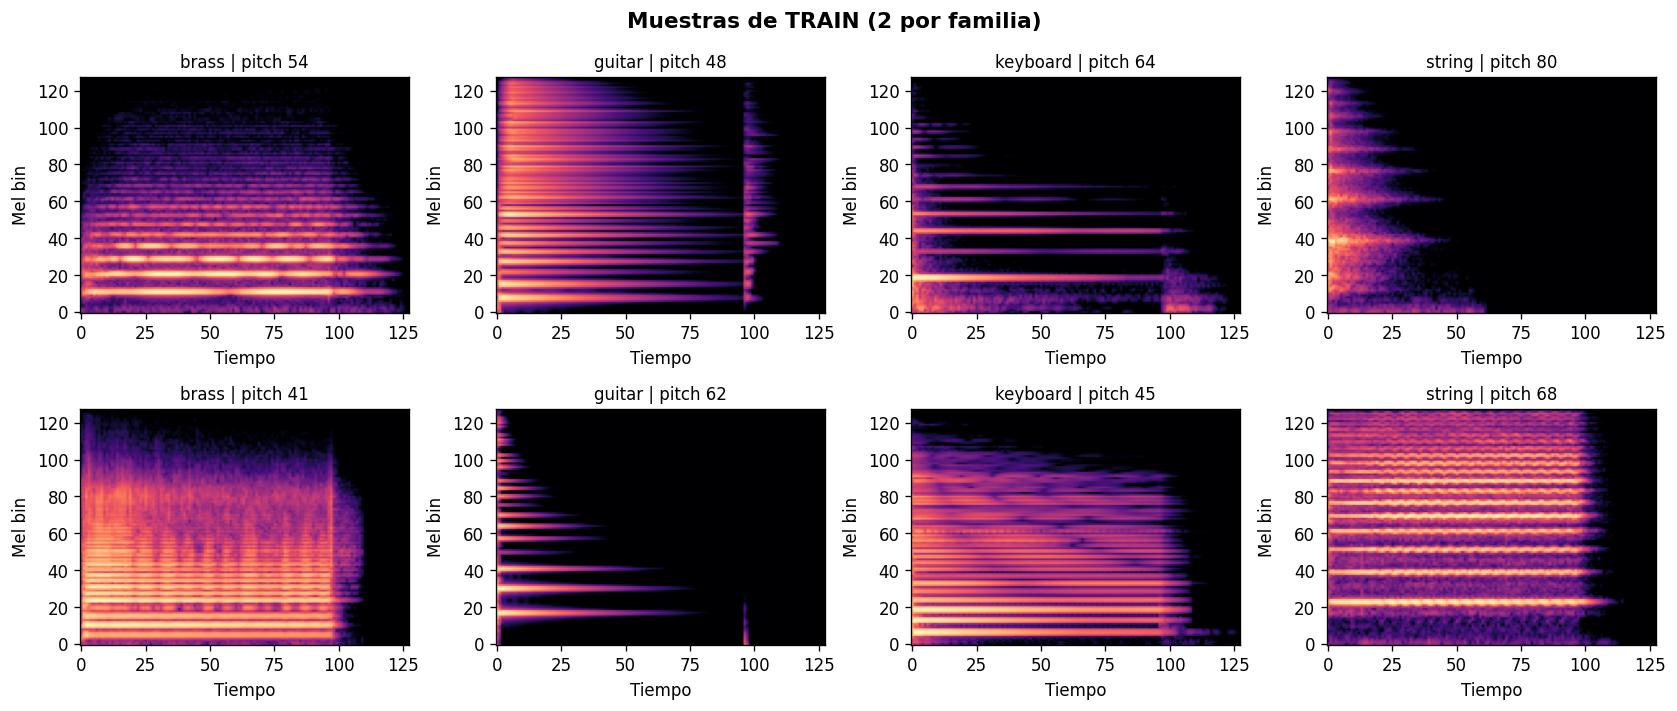

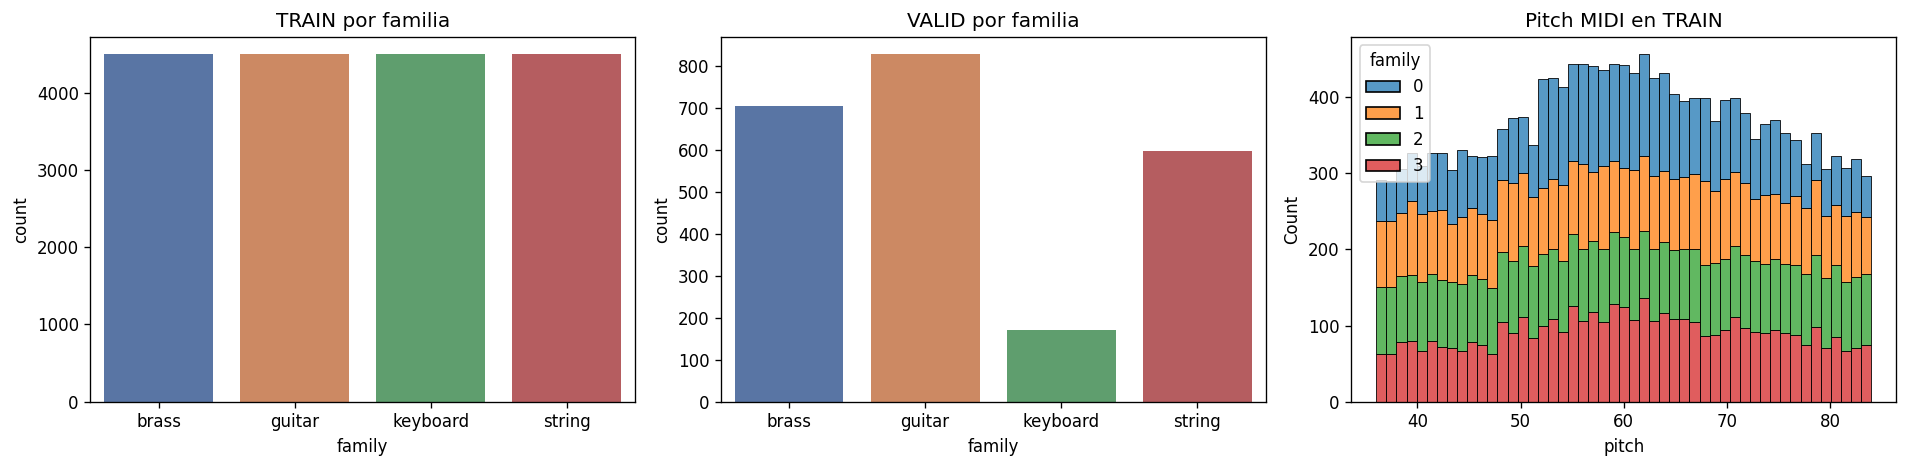

[INFO] Cobertura de pitch por familia (TRAIN):
  brass   : 49 pitches | min=36 max=84 | n=4500
  guitar  : 49 pitches | min=36 max=84 | n=4500
  keyboard: 49 pitches | min=36 max=84 | n=4500
  string  : 49 pitches | min=36 max=84 | n=4500


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), dpi=120)
fig.suptitle('Muestras de TRAIN (2 por familia)', fontsize=13, fontweight='bold')
for col, f in enumerate(range(NUM_FAMILIES)):
    idx = (y_train == f).nonzero(as_tuple=True)[0]
    for row in range(2):
        i = idx[row].item()
        ax = axes[row, col]
        ax.imshow(X_train[i, 0].numpy(), origin='lower', aspect='auto',
                  cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[f]} | pitch {int(p_train[i])}', fontsize=10)
        ax.set_xlabel('Tiempo')
        ax.set_ylabel('Mel bin')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_train.png', dpi=120, bbox_inches='tight')
plt.show()

df_train = pd.DataFrame({'family': y_train.numpy(), 'pitch': p_train.numpy()})
df_val = pd.DataFrame({'family': y_val.numpy(), 'pitch': p_val.numpy()})

fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=120)
sns.countplot(data=df_train, x='family', ax=axes[0], palette='deep')
axes[0].set_title('TRAIN por familia')
axes[0].set_xticklabels(FAMILY_NAMES)
sns.countplot(data=df_val, x='family', ax=axes[1], palette='deep')
axes[1].set_title('VALID por familia')
axes[1].set_xticklabels(FAMILY_NAMES)
sns.histplot(data=df_train, x='pitch', hue='family', multiple='stack',
             bins=NUM_PITCHES, ax=axes[2], palette='tab10')
axes[2].set_title('Pitch MIDI en TRAIN')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cobertura_condiciones.png', dpi=120, bbox_inches='tight')
plt.show()

print('[INFO] Cobertura de pitch por familia (TRAIN):')
for f in range(NUM_FAMILIES):
    vals = df_train[df_train['family'] == f]['pitch']
    print(f'  {FAMILY_NAMES[f]:8s}: {vals.nunique():2d} pitches | '
          f'min={vals.min()} max={vals.max()} | n={len(vals)}')

## 5. Arquitectura del C-VAE jerárquico residual

### ¿Qué se hace a continuación?
Se define un C-VAE convolucional jerárquico de dos niveles (`CondVAE`) con:
- **CoordConv**: canales normalizados `(frecuencia, tiempo)` en `[-1, 1]` para que encoder y decoder conozcan la posición temporal (ataque/sustain/release) y espectral.
- **Encoder residual** (`128 → 64 → 32 → 16 → 8 → 4`) con `GroupNorm + SiLU + FiLM(familia, pitch)` y `SelfAttention2d` en `8×8`.
- **Latente global `z₁` (64 dims)**: captura duración, envolvente global, timbre e intensidad.
- **Latente espacial-temporal `z₂` (`6 × 16 × 16`)**: cada celda representa un bloque de `8×8` del espectrograma, con **prior condicional aprendido `p(z₂ | z₁, c)`** y posterior residual `q(z₂ | x, z₁, c)`.
- **Decoder residual** (`8 → 16 → 32 → 64 → 128`) modulado por `(c, z₁)` vía FiLM, con `SelfAttention2d` en `8×8` y `16×16` y ruido espacial con compuerta sigmoide (`gated_noise`) en `32×32`, `64×64` y `128×128`.

### ¿Por qué se hace?
El cuello FC anterior (`16384 → 256 → 128`) destruía la variación local y promediaba los armónicos. Separar un latente global `z₁` (coherencia de nota) y un latente espacial `z₂` con prior condicional aprendido `p(z₂ | z₁, c)` evita el cuello de botella, mientras `GroupNorm` preserva el rango dinámico por muestra sin mezclar estadísticas entre familias. Las compuertas de ruido aprendidas permiten sintetizar micro-textura estocástica (arco de `string`, soplido de `brass`) solo en las regiones activas donde hace falta.


In [5]:
class FiLM(nn.Module):
    """Modulación por escala y desplazamiento a partir del embedding condicional."""
    def __init__(self, cond_dim, channels):
        super().__init__()
        self.proj = nn.Linear(cond_dim, channels * 2)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, h, c):
        scale, shift = self.proj(c).chunk(2, dim=1)
        return h * (1.0 + scale[:, :, None, None]) + shift[:, :, None, None]


class ResBlock(nn.Module):
    """Bloque residual con GroupNorm, SiLU, FiLM y ruido espacial opcional con compuerta."""
    def __init__(self, in_ch, out_ch, cond_dim, groups=8, gated_noise=False):
        super().__init__()
        g1 = min(groups, in_ch)
        while in_ch % g1 != 0:
            g1 -= 1
        g2 = min(groups, out_ch)
        while out_ch % g2 != 0:
            g2 -= 1
        self.norm1 = nn.GroupNorm(g1, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.film = FiLM(cond_dim, out_ch)
        self.norm2 = nn.GroupNorm(g2, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        self.gated_noise = gated_noise
        if gated_noise:
            self.noise_gate = nn.Conv2d(out_ch, out_ch, 1)
            nn.init.zeros_(self.noise_gate.weight)
            nn.init.constant_(self.noise_gate.bias, -2.5)
            self.noise_amp = nn.Parameter(torch.full((1, out_ch, 1, 1), 0.06))

    def forward(self, x, c, noise_scale=1.0):
        h = self.conv1(F.silu(self.norm1(x)))
        h = self.film(h, c)
        if self.gated_noise and noise_scale > 0.0:
            gate = torch.sigmoid(self.noise_gate(h))
            h = h + (self.noise_amp * gate * noise_scale) * torch.randn_like(h)
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SelfAttention2d(nn.Module):
    """Auto-atención espacial 2D para coordinar armónicos y envolvente global."""
    def __init__(self, ch, heads=4, groups=8):
        super().__init__()
        g = min(groups, ch)
        while ch % g != 0:
            g -= 1
        self.norm = nn.GroupNorm(g, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)
        self.heads = heads
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        q, k, v = self.qkv(h).reshape(B, 3, self.heads, C // self.heads, H * W).unbind(1)
        attn = torch.softmax((q.transpose(-1, -2) @ k) / math.sqrt(C // self.heads), dim=-1)
        out = (attn @ v.transpose(-1, -2)).transpose(-1, -2).reshape(B, C, H, W)
        return x + self.proj(out)


class CondVAE(nn.Module):
    """C-VAE jerárquico residual con latente global z1 y espacial z2."""
    def __init__(self, z1_dim=64, z2_ch=6, base_ch=32, cond_dim=128,
                 num_families=NUM_FAMILIES, num_pitches=NUM_PITCHES):
        super().__init__()
        self.latent_dim = z1_dim
        self.z1_dim = z1_dim
        self.z2_ch = z2_ch
        self.cond_dim = cond_dim

        self.family_emb = nn.Embedding(num_families, 32)
        self.pitch_emb = nn.Embedding(num_pitches, 32)
        self.cond_mlp = nn.Sequential(
            nn.Linear(64, cond_dim), nn.SiLU(), nn.Linear(cond_dim, cond_dim)
        )

        f_lin = torch.linspace(-1.0, 1.0, IMG_SIZE)
        t_lin = torch.linspace(-1.0, 1.0, IMG_SIZE)
        fg, tg = torch.meshgrid(f_lin, t_lin, indexing='ij')
        coords_128 = torch.stack([fg, tg], dim=0).unsqueeze(0)
        self.register_buffer('coords_128', coords_128, persistent=False)
        self.register_buffer(
            'coords_16',
            F.interpolate(coords_128, size=(16, 16), mode='bilinear', align_corners=False),
            persistent=False,
        )

        ch = [base_ch, base_ch * 2, base_ch * 4, base_ch * 6]  # [32, 64, 128, 192]
        self.ch = ch

        # Encoder: 128 -> 64 -> 32 -> 16 -> 8 -> 4
        self.enc_in = nn.Conv2d(3, ch[0], 3, padding=1)
        self.enc_128 = ResBlock(ch[0], ch[0], cond_dim)
        self.down_128 = nn.Conv2d(ch[0], ch[1], 4, stride=2, padding=1)
        self.enc_64 = ResBlock(ch[1], ch[1], cond_dim)
        self.down_64 = nn.Conv2d(ch[1], ch[2], 4, stride=2, padding=1)
        self.enc_32 = ResBlock(ch[2], ch[2], cond_dim)
        self.down_32 = nn.Conv2d(ch[2], ch[2], 4, stride=2, padding=1)
        self.enc_16 = nn.ModuleList([
            ResBlock(ch[2], ch[2], cond_dim),
            ResBlock(ch[2], ch[2], cond_dim),
        ])
        self.down_16 = nn.Conv2d(ch[2], ch[3], 4, stride=2, padding=1)
        self.enc_8 = nn.ModuleList([
            ResBlock(ch[3], ch[3], cond_dim),
            SelfAttention2d(ch[3]),
            ResBlock(ch[3], ch[3], cond_dim),
        ])

        self.enc_to_4 = nn.Conv2d(ch[3], ch[3], 4, stride=2, padding=1)
        self.fc_z1 = nn.Sequential(nn.Linear(ch[3] * 16 + cond_dim, 384), nn.SiLU())
        self.fc_mu1 = nn.Linear(384, z1_dim)
        self.fc_lv1 = nn.Linear(384, z1_dim)

        # Decoder conditioning (c + z1)
        dc = 192
        self.dec_cond_mlp = nn.Sequential(
            nn.Linear(cond_dim + z1_dim, dc), nn.SiLU(), nn.Linear(dc, dc)
        )
        self.fc_dec8 = nn.Sequential(
            nn.Linear(dc, 384), nn.SiLU(), nn.Linear(384, ch[3] * 8 * 8), nn.SiLU()
        )
        self.dec_8 = nn.ModuleList([
            ResBlock(ch[3], ch[3], dc),
            SelfAttention2d(ch[3]),
            ResBlock(ch[3], ch[3], dc),
        ])
        self.up_8 = nn.Upsample(scale_factor=2, mode='nearest')
        self.dec_16_pre = ResBlock(ch[3] + 2, ch[2], dc)

        # Prior condicional p(z2 | z1, c) y posterior residual q(z2 | x, z1, c) en 16x16
        self.prior_z2 = nn.Sequential(
            nn.Conv2d(ch[2], ch[2], 3, padding=1), nn.SiLU(),
            nn.Conv2d(ch[2], z2_ch * 2, 3, padding=1),
        )
        self.post_z2 = nn.Sequential(
            nn.Conv2d(ch[2] * 2, ch[2], 3, padding=1), nn.GroupNorm(8, ch[2]), nn.SiLU(),
            nn.Conv2d(ch[2], z2_ch * 2, 3, padding=1),
        )

        # Decoder: 16 -> 32 -> 64 -> 128
        self.dec_16_post = nn.ModuleList([
            ResBlock(ch[2] + z2_ch, ch[2], dc),
            SelfAttention2d(ch[2]),
            ResBlock(ch[2], ch[2], dc),
        ])
        self.up_16 = nn.Upsample(scale_factor=2, mode='nearest')
        self.dec_32 = nn.ModuleList([
            ResBlock(ch[2], ch[2], dc),
            ResBlock(ch[2], ch[1], dc, gated_noise=True),
        ])
        self.up_32 = nn.Upsample(scale_factor=2, mode='nearest')
        self.dec_64 = nn.ModuleList([
            ResBlock(ch[1], ch[1], dc, gated_noise=True),
            ResBlock(ch[1], ch[0], dc),
        ])
        self.up_64 = nn.Upsample(scale_factor=2, mode='nearest')
        self.dec_128 = ResBlock(ch[0], ch[0], dc, gated_noise=True)

        self.out_norm = nn.GroupNorm(8, ch[0])
        self.out_conv = nn.Conv2d(ch[0], 1, 3, padding=1)

    def condition(self, family, pitch):
        p = (pitch - PITCH_MIN).clamp(0, NUM_PITCHES - 1)
        return self.cond_mlp(torch.cat([self.family_emb(family), self.pitch_emb(p)], dim=1))

    def encode_features(self, x, c):
        B = x.shape[0]
        coords = self.coords_128.expand(B, -1, -1, -1)
        h = self.enc_in(torch.cat([x, coords], dim=1))
        h = self.enc_128(h, c)
        h = self.enc_64(self.down_128(h), c)
        h = self.enc_32(self.down_64(h), c)
        h = self.down_32(h)
        for blk in self.enc_16:
            h = blk(h, c)
        feat_16 = h
        h = self.down_16(feat_16)
        for blk in self.enc_8:
            h = blk(h, c) if isinstance(blk, ResBlock) else blk(h)
        feat_4 = F.silu(self.enc_to_4(h)).flatten(1)
        b = self.fc_z1(torch.cat([feat_4, c], dim=1))
        return self.fc_mu1(b), self.fc_lv1(b).clamp(-8.0, 4.0), feat_16

    def encode(self, x, family, pitch):
        """Devuelve (mu1, logvar1) del latente global para análisis/PCA."""
        c = self.condition(family, pitch)
        mu1, lv1, _ = self.encode_features(x, c)
        return mu1, lv1

    def decode_to_16(self, z1, c):
        B = z1.shape[0]
        dc = self.dec_cond_mlp(torch.cat([c, z1], dim=1))
        h = self.fc_dec8(dc).view(B, self.ch[3], 8, 8)
        for blk in self.dec_8:
            h = blk(h, dc) if isinstance(blk, ResBlock) else blk(h)
        h = self.up_8(h)
        c16 = self.coords_16.expand(B, -1, -1, -1)
        h_16 = self.dec_16_pre(torch.cat([h, c16], dim=1), dc)
        mu_p2, lv_p2 = self.prior_z2(h_16).chunk(2, dim=1)
        return h_16, dc, mu_p2, lv_p2.clamp(-8.0, 4.0)

    def decode_from_16(self, h_16, z2, dc):
        h = torch.cat([h_16, z2], dim=1)
        for blk in self.dec_16_post:
            h = blk(h, dc) if isinstance(blk, ResBlock) else blk(h)
        h = self.up_16(h)
        for blk in self.dec_32:
            h = blk(h, dc)
        h = self.up_32(h)
        for blk in self.dec_64:
            h = blk(h, dc)
        h = self.dec_128(self.up_64(h), dc)
        return torch.tanh(self.out_conv(F.silu(self.out_norm(h))))

    def forward(self, x, family, pitch, deterministic=False):
        c = self.condition(family, pitch)
        mu1, lv1, feat_16 = self.encode_features(x, c)
        if deterministic:
            z1 = mu1
        else:
            z1 = mu1 + torch.exp(0.5 * lv1) * torch.randn_like(mu1)
        h_16, dc, mu_p2, lv_p2 = self.decode_to_16(z1, c)
        dmu_q2, lv_q2 = self.post_z2(torch.cat([feat_16, h_16], dim=1)).chunk(2, dim=1)
        lv_q2 = lv_q2.clamp(-8.0, 4.0)
        mu_q2 = mu_p2 + dmu_q2
        if deterministic:
            z2 = mu_q2
        else:
            z2 = mu_q2 + torch.exp(0.5 * lv_q2) * torch.randn_like(mu_q2)
        recon = self.decode_from_16(h_16, z2, dc)
        return recon, z1, mu1, lv1, mu_p2, lv_p2, mu_q2, lv_q2

    @torch.no_grad()
    def sample_prior(self, z1, family, pitch, tau2=1.0):
        c = self.condition(family, pitch)
        h_16, dc, mu_p2, lv_p2 = self.decode_to_16(z1, c)
        z2 = mu_p2 + (tau2 * torch.exp(0.5 * lv_p2)) * torch.randn_like(mu_p2)
        return self.decode_from_16(h_16, z2, dc)


model_test = CondVAE(z1_dim=64, z2_ch=6, base_ch=32, cond_dim=128).to(device)
n_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f'[INFO] CondVAE jerárquico — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

with torch.no_grad():
    dummy = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=device)
    fam_d = torch.tensor([0, 1], device=device)
    pit_d = torch.tensor([60, 72], device=device)
    out, z1_d, mu1_d, lv1_d, mup2_d, lvp2_d, muq2_d, lvq2_d = model_test(dummy, fam_d, pit_d)
print(f'[INFO] Salida: {tuple(out.shape)} | z1: {tuple(mu1_d.shape)} | z2: {tuple(muq2_d.shape)}')
del model_test, dummy, out, z1_d, mu1_d, lv1_d, mup2_d, lvp2_d, muq2_d, lvq2_d
torch.cuda.empty_cache()


[INFO] CondVAE jerárquico — parámetros entrenables: 14,270,281 (14.27 M)
[INFO] Salida: (2, 1, 128, 128) | z1: (2, 64) | z2: (2, 6, 16, 16)


## 6. Pérdida multi-escala de textura, vocoder Griffin-Lim y utilidades

### ¿Qué se hace a continuación?
Se definen:
- la pérdida de reconstrucción compuesta en FP32:
  `L_rec = L1 + 0.3·L_grad + 1.5·L_fft + 1.5·L_tex`
  donde `L_grad` compara derivadas en `128×128` y `64×64`, `L_fft` compara el espectro de modulación temporal 1D (con peso extra en modulaciones rápidas) y la FFT 2D en log-magnitud, y `L_tex` iguala desvío y rugosidad temporal/espectral local en parches `8×8`;
- regularización KL jerárquica (`KL1` y `KL2`) con **warmup de 8 épocas**, **free bits** (`0.20` nats/dim en `z₁`, `0.03` nats/dim en `z₂`), control proporcional suave hacia objetivos (`KL1_TARGET=45`, `KL2_TARGET=120`) y **IMQ-MMD** sobre el posterior agregado de `z₁`;
- el vocoder Griffin-Lim que revierte `(dB+40)/40`, sintetiza con la escala mel correcta (`htk=True, norm=None`) y limpia el audio con compuerta suave, fade y normalización única;
- los hiperparámetros del entrenamiento (`EPOCHS=70`, `MAX_TRAIN_MINUTES=68` con reanudación automática).

### ¿Por qué se hace?
La `L1` pura promedia las micro-modulaciones temporales (vibrato, ruido de arco en `string`, transientes de `keyboard`) cuando su fase no es fija. La pérdida `L_fft` en magnitud es **invariante a fase** y `L_tex` exige que cada parche `8×8` conserve la energía de variación temporal (`|∂_t|`, `|∂²_t|`) y espectral real. El warmup de 8 épocas con *free bits* evita el colapso prematuro del latente, y el IMQ-MMD asegura que la distribución agregada de `z₁` coincida con `N(0, I)` al muestrear del prior.


In [6]:
# ── Hiperparámetros ─────────────────────────────────────────────────────────
Z1_DIM = 64
Z2_CH = 2
LATENT_DIM = Z1_DIM
BASE_CH = 32
COND_DIM = 128
LR = 4e-4
WEIGHT_DECAY = 1e-4
EPOCHS = 70
WARMUP_EPOCHS = 3
PATIENCE = 15

# Regularización KL jerárquica + MMD
BETA1_INIT, BETA2_INIT = 5e-4, 3e-4
KL1_TARGET, KL2_TARGET = 35.0, 25.0
BETA1_MIN, BETA1_MAX = 1e-4, 5e-3
BETA2_MIN, BETA2_MAX = 5e-5, 5e-3
FREE_BITS_1 = 0.20
FREE_BITS_2 = 0.0
KL_WARMUP_EPOCHS = 8
SAMPLE_EVAL_EVERY = 2
LAMBDA_GRAD = 0.3
LAMBDA_FFT = 1.5
LAMBDA_TEX = 1.5
LAMBDA_MMD = 0.05

MAX_TRAIN_MINUTES = 68
RESUME = True

# ── Audio ───────────────────────────────────────────────────────────────────
SR = 16000
N_FFT = 2048
HOP = 500
N_MELS = 128
GATE_DB = -40.0
FADE_MS = 15


# ── Pérdidas ────────────────────────────────────────────────────────────────
def recon_losses(recon, x):
    """L1 + gradientes multi-escala + FFT temporal/2D + textura local por parche."""
    recon = recon.float()
    x = x.float()
    l1 = F.l1_loss(recon, x)

    def grad_l1(a, b):
        dt = F.l1_loss(a[:, :, :, 1:] - a[:, :, :, :-1], b[:, :, :, 1:] - b[:, :, :, :-1])
        df = F.l1_loss(a[:, :, 1:, :] - a[:, :, :-1, :], b[:, :, 1:, :] - b[:, :, :-1, :])
        d2t = F.l1_loss(
            a[:, :, :, 2:] - 2.0 * a[:, :, :, 1:-1] + a[:, :, :, :-2],
            b[:, :, :, 2:] - 2.0 * b[:, :, :, 1:-1] + b[:, :, :, :-2],
        )
        return dt + df + d2t

    l_grad = grad_l1(recon, x) + 0.5 * grad_l1(F.avg_pool2d(recon, 2), F.avg_pool2d(x, 2))

    # Espectro de modulación temporal (invariante a fase) + FFT 2D
    rf1 = torch.log1p(torch.abs(torch.fft.rfft(recon, dim=-1, norm='ortho')))
    xf1 = torch.log1p(torch.abs(torch.fft.rfft(x, dim=-1, norm='ortho')))
    rf2 = torch.log1p(torch.abs(torch.fft.rfft2(recon, norm='ortho')))
    xf2 = torch.log1p(torch.abs(torch.fft.rfft2(x, norm='ortho')))
    l_fft = (
        F.l1_loss(rf1, xf1)
        + 2.0 * F.l1_loss(rf1[:, :, :, 8:], xf1[:, :, :, 8:])
        + F.l1_loss(rf2, xf2)
    )

    # Estadísticas locales en parches 8x8 (stride 4)
    def patch_stats(u):
        dt_abs = F.pad(torch.abs(u[:, :, :, 1:] - u[:, :, :, :-1]), (0, 1, 0, 0))
        d2t_abs = F.pad(
            torch.abs(u[:, :, :, 2:] - 2.0 * u[:, :, :, 1:-1] + u[:, :, :, :-2]),
            (1, 1, 0, 0),
        )
        df_abs = F.pad(torch.abs(u[:, :, 1:, :] - u[:, :, :-1, :]), (0, 0, 0, 1))
        m1 = F.avg_pool2d(u, 8, stride=4)
        m2 = F.avg_pool2d(u * u, 8, stride=4)
        std = torch.sqrt(torch.clamp(m2 - m1 * m1, min=0.0) + 1e-6)
        return (
            std,
            F.avg_pool2d(dt_abs, 8, stride=4),
            F.avg_pool2d(d2t_abs, 8, stride=4),
            F.avg_pool2d(df_abs, 8, stride=4),
        )

    rs, rdt, rd2t, rdf = patch_stats(recon)
    xs, xdt, xd2t, xdf = patch_stats(x)
    l_tex = (
        F.l1_loss(rs, xs)
        + 2.5 * F.l1_loss(rdt, xdt)
        + 2.5 * F.l1_loss(rd2t, xd2t)
        + F.l1_loss(rdf, xdf)
    )
    l_rec_obj = l1 + LAMBDA_GRAD * l_grad + LAMBDA_FFT * l_fft + LAMBDA_TEX * l_tex
    return l_rec_obj, l1, l_grad, l_fft, l_tex


def imq_mmd(z, z_prior=None):
    """IMQ-MMD multi-escala (Tolstikhin et al., WAE) entre z y N(0, I)."""
    z = z.float()
    if z_prior is None:
        z_prior = torch.randn_like(z)
    n, d = z.shape
    if n < 2:
        return z.new_zeros(())
    c_base = 2.0 * d
    scales = (0.1, 0.2, 0.5, 1.0, 2.0, 5.0)
    d_zz = torch.cdist(z, z, p=2).pow(2)
    d_pp = torch.cdist(z_prior, z_prior, p=2).pow(2)
    d_zp = torch.cdist(z, z_prior, p=2).pow(2)
    eye = torch.eye(n, device=z.device, dtype=torch.bool)
    mmd = z.new_zeros(())
    for s in scales:
        c = c_base * s
        k_zz = (c / (c + d_zz)).masked_fill(eye, 0.0).sum() / (n * (n - 1))
        k_pp = (c / (c + d_pp)).masked_fill(eye, 0.0).sum() / (n * (n - 1))
        k_zp = (c / (c + d_zp)).mean()
        mmd = mmd + (k_zz + k_pp - 2.0 * k_zp)
    return mmd


def vae_loss(recon, x, z1, mu1, lv1, mu_p2, lv_p2, mu_q2, lv_q2, beta1, beta2):
    l_rec_obj, l1, l_grad, l_fft, l_tex = recon_losses(recon, x)
    mu1, lv1 = mu1.float(), lv1.float()
    mu_p2, lv_p2 = mu_p2.float(), lv_p2.float()
    mu_q2, lv_q2 = mu_q2.float(), lv_q2.float()

    kl1_per_dim = -0.5 * (1.0 + lv1 - mu1.pow(2) - lv1.exp())
    kl1_raw = kl1_per_dim.sum(dim=1).mean()
    kl1_fb = torch.clamp(kl1_per_dim, min=FREE_BITS_1).sum(dim=1).mean()

    kl2_per_dim = 0.5 * (
        (mu_q2 - mu_p2).pow(2) / lv_p2.exp()
        + (lv_q2 - lv_p2).exp()
        - 1.0
        - (lv_q2 - lv_p2)
    )
    kl2_raw = kl2_per_dim.sum(dim=(1, 2, 3)).mean()
    kl2_fb = torch.clamp(kl2_per_dim, min=FREE_BITS_2).sum(dim=(1, 2, 3)).mean()

    mmd = imq_mmd(z1)
    total = l_rec_obj + beta1 * kl1_fb + beta2 * kl2_fb + LAMBDA_MMD * mmd
    return (
        total, l_rec_obj, l1, l_grad, l_fft, l_tex,
        kl1_raw, kl2_raw, mmd,
        kl1_per_dim.mean(dim=0),
        kl2_per_dim.mean(dim=0).flatten(),
    )


def betas_en_epoch(epoch, beta1_act=BETA1_INIT, beta2_act=BETA2_INIT,
                   kl1_prev=None, kl2_prev=None):
    """Warmup lineal de 0 a target en KL_WARMUP_EPOCHS y luego ajuste proporcional."""
    if epoch < KL_WARMUP_EPOCHS:
        frac = epoch / max(1, KL_WARMUP_EPOCHS)
        return BETA1_INIT * frac, BETA2_INIT * frac
    if kl1_prev is not None and np.isfinite(kl1_prev):
        b1 = float(np.clip(beta1_act * math.exp(0.5 * (kl1_prev / KL1_TARGET - 1.0)), BETA1_MIN, BETA1_MAX))
    else:
        b1 = beta1_act
    if kl2_prev is not None and np.isfinite(kl2_prev):
        b2 = float(np.clip(beta2_act * math.exp(0.5 * (kl2_prev / KL2_TARGET - 1.0)), BETA2_MIN, BETA2_MAX))
    else:
        b2 = beta2_act
    return b1, b2


# ── Checkpoints ─────────────────────────────────────────────────────────────
def guardar_checkpoint(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    torch.save(payload, tmp)
    os.replace(tmp, path)


def cargar_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)


# ── Vocoder Griffin-Lim ─────────────────────────────────────────────────────
class GriffinLimVocoder:
    """Invierte mel [-1, 1] a audio.

    Coincide con el preprocesado: escala mel HTK, norm=None y dB = 40*v - 40.
    Limpia el resultado con compuerta suave (hiss de Griffin-Lim en silencios),
    fade de 15 ms y una única normalización de pico.
    """

    def __init__(self, sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS):
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.n_mels = n_mels

    @staticmethod
    def _compuerta_suave(wav, sr, umbral_db=-40.0, rodilla_db=8.0, suav_ms=30):
        win = max(1, int(sr * 0.02))
        if len(wav) < win:
            return wav
        env = np.sqrt(np.convolve(wav ** 2, np.ones(win) / win, mode='same'))
        ref = max(float(env.max()), 1e-12)
        db = 20.0 * np.log10(env / ref + 1e-12)
        gan = np.clip((db - (umbral_db - rodilla_db)) / rodilla_db, 0.0, 1.0)
        k = max(1, int(sr * suav_ms / 1000))
        gan = np.convolve(gan, np.ones(k) / k, mode='same')
        return (wav * gan).astype(np.float32)

    def mel_norm_to_audio(self, mel_norm, n_iter=250, gate_db=GATE_DB, fade_ms=FADE_MS):
        mel = np.asarray(mel_norm, dtype=np.float32)
        mel_power = librosa.db_to_power(mel * 40.0 - 40.0, ref=1.0)
        wav = librosa.feature.inverse.mel_to_audio(
            mel_power,
            sr=self.sample_rate,
            n_fft=self.n_fft,
            win_length=self.n_fft,
            hop_length=self.hop_length,
            power=2.0,
            n_iter=n_iter,
            htk=True,
            norm=None,
        )
        wav = np.asarray(wav, dtype=np.float32)
        if wav.size == 0:
            return wav

        objetivo = int(mel.shape[1] * self.hop_length)
        if wav.size < objetivo:
            wav = np.pad(wav, (0, objetivo - wav.size))
        else:
            wav = wav[:objetivo]

        wav = wav - float(wav.mean())
        if gate_db is not None:
            wav = self._compuerta_suave(wav, self.sample_rate, umbral_db=gate_db)

        nf = int(self.sample_rate * fade_ms / 1000)
        if nf > 0 and len(wav) > 2 * nf:
            wav[:nf] *= np.linspace(0.0, 1.0, nf, dtype=np.float32)
            wav[-nf:] *= np.linspace(1.0, 0.0, nf, dtype=np.float32)

        pico = float(np.max(np.abs(wav)))
        if pico > 1e-7:
            wav = wav / pico * 0.95
        return wav.astype(np.float32)


def to_py(obj):
    """Convierte tipos numpy/torch a tipos serializables en JSON."""
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, float) and not math.isfinite(obj):
        return None
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, torch.Tensor):
        return obj.detach().cpu().tolist()
    return obj


vocoder = GriffinLimVocoder()
print('[INFO] Vocoder Griffin-Lim listo.')
print(f'[INFO] Config: z1={Z1_DIM} | z2={Z2_CH}x16x16 | base_ch={BASE_CH} | cond_dim={COND_DIM} | '
      f'batch={BATCH_SIZE} | lr={LR} | epochs={EPOCHS} | kl_targets=({KL1_TARGET}, {KL2_TARGET}) | '
      f'time_budget={MAX_TRAIN_MINUTES} min')


[INFO] Vocoder Griffin-Lim listo.
[INFO] Config: z1=64 | z2=2x16x16 | base_ch=32 | cond_dim=128 | batch=64 | lr=0.0004 | epochs=70 | kl_targets=(35.0, 25.0) | time_budget=68 min


## 7. Smoke test antes de entrenar

### ¿Qué se hace a continuación?
Se crea un modelo temporal, se procesa **un solo batch** con forward, pérdida, backward y un paso de optimizador, se generan 4 muestras desde el prior y se pasa una de ellas por Griffin-Lim.

### ¿Por qué se hace?
Es el seguro contra el escenario que querés evitar: entrenar 40 minutos y que recién ahí aparezca una excepción. Acá se verifican shapes, pérdida finita, gradientes, decodificación, rango de salida y que el vocoder produzca audio no silencioso. Cuesta menos de un minuto y descarta los errores más caros.

In [7]:
torch.manual_seed(SEED)
model_test = CondVAE(z1_dim=Z1_DIM, z2_ch=Z2_CH, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
opt_test = torch.optim.AdamW(model_test.parameters(), lr=1e-4)
scaler_test = torch.cuda.amp.GradScaler(enabled=use_amp)

xb, fb, pb = next(iter(loader_train))
xb = xb.to(device)
fb = fb.to(device)
pb = pb.to(device)

model_test.train()
opt_test.zero_grad(set_to_none=True)
with torch.cuda.amp.autocast(enabled=use_amp):
    recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2 = model_test(xb, fb, pb)
loss, l_rec_obj, rl1, l_grad, l_fft, l_tex, kl1, kl2, mmd, _, _ = vae_loss(
    recon, xb, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, BETA1_INIT, BETA2_INIT
)

print(f'[INFO] recon={tuple(recon.shape)} | z1={tuple(mu1.shape)} | z2={tuple(muq2.shape)}')
print(f'[INFO] loss={loss.item():.4f} | rec_obj={l_rec_obj.item():.4f} | l1={rl1.item():.4f} | '
      f'fft={l_fft.item():.4f} | tex={l_tex.item():.4f} | kl1={kl1.item():.1f} | kl2={kl2.item():.1f}')
assert torch.isfinite(loss).item(), 'La pérdida no es finita'

scaler_test.scale(loss).backward()
scaler_test.unscale_(opt_test)
torch.nn.utils.clip_grad_norm_(model_test.parameters(), 1.0)
scaler_test.step(opt_test)
scaler_test.update()
print('[OK] Forward, backward y optimizer step funcionan.')

model_test.eval()
with torch.no_grad():
    z1_s = torch.randn(4, Z1_DIM, device=device)
    fam_s = torch.tensor([0, 1, 2, 3], device=device)
    pit_s = torch.tensor([60, 60, 60, 60], device=device)
    with torch.cuda.amp.autocast(enabled=use_amp):
        muestras = model_test.sample_prior(z1_s, fam_s, pit_s)

print(f'[INFO] Muestras: {tuple(muestras.shape)} | '
      f'rango=[{muestras.min():.3f}, {muestras.max():.3f}] | '
      f'finite={torch.isfinite(muestras).all().item()}')
assert torch.isfinite(muestras).all().item(), 'Las muestras contienen NaN/Inf'

wav_test = vocoder.mel_norm_to_audio(muestras[0, 0].cpu().numpy(), n_iter=32)
print(f'[INFO] Audio de prueba: {wav_test.shape} | max|y|={np.abs(wav_test).max():.4f}')
assert np.abs(wav_test).max() > 1e-3, 'Griffin-Lim devolvió audio silencioso'

del model_test, opt_test, scaler_test, xb, fb, pb, recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, muestras
torch.cuda.empty_cache()
print('[OK] Smoke test completo. Podés entrenar con tranquilidad.')


[INFO] recon=(64, 1, 128, 128) | z1=(64, 64) | z2=(64, 2, 16, 16)
[INFO] loss=2.2519 | rec_obj=2.2341 | l1=0.9895 | fft=0.2163 | tex=0.5115 | kl1=0.1 | kl2=37.5
[OK] Forward, backward y optimizer step funcionan.
[INFO] Muestras: (4, 1, 128, 128) | rango=[-0.277, 0.998] | finite=True
[INFO] Audio de prueba: (64000,) | max|y|=0.9500
[OK] Smoke test completo. Podés entrenar con tranquilidad.


## 8. Piloto de 3 epochs

### ¿Qué se hace a continuación?
Se entrena un modelo temporal durante 3 epochs con 2.000 muestras estratificadas (500 por familia). No se guarda: es solo una prueba de convergencia.

### ¿Por qué se hace?
El smoke test valida que el código no explota; el piloto valida que el modelo **aprende**. Si la pérdida baja en 3 epochs con 2.000 muestras, hay buenas chances de que las 80 epochs completas converjan. Si no baja, conviene ajustar `LR` o `β` antes de gastar 40 minutos.

In [8]:
RUN_PILOT = True

if RUN_PILOT:
    torch.manual_seed(SEED)
    idx_pilot = []
    for f in range(NUM_FAMILIES):
        idx_f = (y_train == f).nonzero(as_tuple=True)[0]
        perm = torch.randperm(len(idx_f))[:500]
        idx_pilot.append(idx_f[perm])
    idx_pilot = torch.cat(idx_pilot)

    ds_pilot = TensorDataset(X_train[idx_pilot], y_train[idx_pilot], p_train[idx_pilot])
    loader_pilot = DataLoader(ds_pilot, batch_size=BATCH_SIZE, shuffle=True,
                              drop_last=True, num_workers=0, pin_memory=use_amp)

    model_pilot = CondVAE(z1_dim=Z1_DIM, z2_ch=Z2_CH, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
    opt_pilot = torch.optim.AdamW(model_pilot.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scaler_pilot = torch.cuda.amp.GradScaler(enabled=use_amp)

    print(f'[INFO] Piloto: {len(ds_pilot)} muestras | {len(loader_pilot)} batches')
    for ep in range(3):
        model_pilot.train()
        acum, n = 0.0, 0
        b1, b2 = betas_en_epoch(ep + 1)
        for xb, fb, pb in tqdm(loader_pilot, desc=f'Piloto {ep+1}/3', leave=False):
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)
            opt_pilot.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2 = model_pilot(xb, fb, pb)
            loss, rec_obj, rl1, _, _, _, kl1, kl2, _, _, _ = vae_loss(
                recon, xb, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, b1, b2
            )
            if not torch.isfinite(loss):
                continue
            scaler_pilot.scale(loss).backward()
            scaler_pilot.unscale_(opt_pilot)
            torch.nn.utils.clip_grad_norm_(model_pilot.parameters(), 1.0)
            scaler_pilot.step(opt_pilot)
            scaler_pilot.update()
            acum += loss.item()
            n += 1
        print(f'[INFO] Piloto epoch {ep+1}: loss={acum/max(n,1):.4f} | batches={n}')

    del model_pilot, opt_pilot, scaler_pilot
    torch.cuda.empty_cache()
    print('[OK] Piloto finalizado. Si la loss bajó, seguí con el entrenamiento completo.')
else:
    print('[INFO] Piloto desactivado (RUN_PILOT=False).')


[INFO] Piloto: 2000 muestras | 31 batches


Piloto 1/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 1: loss=1.2876 | batches=31


Piloto 2/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 2: loss=0.8925 | batches=31


Piloto 3/3:   0%|          | 0/31 [00:00<?, ?it/s]

[INFO] Piloto epoch 3: loss=0.7990 | batches=31
[OK] Piloto finalizado. Si la loss bajó, seguí con el entrenamiento completo.


## 9. Entrenamiento completo del C-VAE jerárquico

### ¿Qué se hace a continuación?
Se entrena el modelo definitivo con AdamW, AMP, warmup + cosine, clipping de gradientes, early stopping y un presupuesto máximo de 68 minutos por sesión (con auto-importación de checkpoints desde `/kaggle/input` para reanudar sin pérdida si hiciera falta una segunda corrida). En cada época después del warmup de KL (`8` épocas), `β₁` y `β₂` se ajustan suavemente para mantener `KL₁ ≈ 45` y `KL₂ ≈ 120`. Se guarda:
- `vae_last.pt` al final de **cada** época, para poder reanudar;
- `vae_best.pt` cuando mejora el objetivo de reconstrucción (`L1 + grad + fft + tex`) en `valid` (a partir de la época `KL_WARMUP_EPOCHS`, para no elegir un checkpoint previo a la regularización KL);
- `historial.csv` con todas las métricas;
- `vae_crash.pt` si ocurre una excepción.


In [9]:
import shutil

model = CondVAE(z1_dim=Z1_DIM, z2_ch=Z2_CH, base_ch=BASE_CH, cond_dim=COND_DIM).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'[INFO] CondVAE jerárquico — parámetros entrenables: {n_params:,} ({n_params/1e6:.2f} M)')

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)



@torch.no_grad()
def evaluar_calidad_prior(model, X_ref, y_ref, p_ref, n_por_fam=6, seed=SEED):
    """Evalúa muestras del prior en valid: acierto de pitch ±1 st (YIN rápido) y hf_time."""
    from scipy.ndimage import uniform_filter1d
    model.eval()
    torch.manual_seed(seed)
    fams, pits, refs = [], [], []
    for f in range(NUM_FAMILIES):
        idx_f = (y_ref == f).nonzero(as_tuple=True)[0]
        if len(idx_f) == 0:
            continue
        step = max(1, len(idx_f) // n_por_fam)
        sel = idx_f[::step][:n_por_fam]
        for idx in sel:
            fams.append(int(f))
            pits.append(int(p_ref[idx].item()))
            refs.append(X_ref[idx])
    f_t = torch.tensor(fams, dtype=torch.long, device=device)
    p_t = torch.tensor(pits, dtype=torch.long, device=device)
    z1 = torch.randn(len(fams), Z1_DIM, device=device)
    with torch.cuda.amp.autocast(enabled=use_amp):
        gen = model.sample_prior(z1, f_t, p_t, tau2=1.0).float().cpu()
    aciertos = []
    for i in range(len(fams)):
        wav = vocoder.mel_norm_to_audio(gen[i, 0].numpy(), n_iter=32)
        f0 = librosa.yin(wav, fmin=librosa.note_to_hz('C1'), fmax=librosa.note_to_hz('C7'), sr=SR, frame_length=2048, hop_length=512)
        f0_ok = f0[np.isfinite(f0) & (f0 > 0)]
        if len(f0_ok) == 0:
            aciertos.append(0.0)
        else:
            midi_pred = float(np.median(librosa.hz_to_midi(f0_ok)))
            aciertos.append(1.0 if abs(midi_pred - pits[i]) <= 1.0 else 0.0)
    pitch_1st = float(np.mean(aciertos))
    hf_gen = float(np.abs(gen[:, 0].numpy() - uniform_filter1d(gen[:, 0].numpy(), 5, axis=2))[:, :, 10:90].mean())
    ref_np = torch.stack(refs)[:, 0].numpy()
    hf_ref = float(np.abs(ref_np - uniform_filter1d(ref_np, 5, axis=2))[:, :, 10:90].mean())
    score = pitch_1st - 0.25 * abs(hf_gen - hf_ref) / max(hf_ref, 1e-4)
    return pitch_1st, hf_gen, hf_ref, score


def lr_para_epoch(epoca):
    """Warmup lineal + coseno (1-based) calculado desde EPOCHS."""
    eta_min = 1e-6
    if epoca <= WARMUP_EPOCHS:
        frac = (epoca - 1) / max(1, WARMUP_EPOCHS - 1)
        return LR * (0.1 + 0.9 * frac)
    prog = (epoca - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
    prog = min(max(prog, 0.0), 1.0)
    return eta_min + (LR - eta_min) * 0.5 * (1.0 + math.cos(math.pi * prog))


scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

config_actual = {
    'arch': 'CondHVAE_v2_1',
    'z1_dim': Z1_DIM,
    'z2_ch': Z2_CH,
    'base_ch': BASE_CH,
    'cond_dim': COND_DIM,
    'batch_size': BATCH_SIZE,
    'lr': LR,
    'weight_decay': WEIGHT_DECAY,
    'beta1_init': BETA1_INIT,
    'beta2_init': BETA2_INIT,
    'kl1_target': KL1_TARGET,
    'kl2_target': KL2_TARGET,
    'kl_warmup_epochs': KL_WARMUP_EPOCHS,
    'lambda_grad': LAMBDA_GRAD,
    'lambda_fft': LAMBDA_FFT,
    'lambda_tex': LAMBDA_TEX,
    'lambda_mmd': LAMBDA_MMD,
    'epochs': EPOCHS,
    'seed': SEED,
}

ckpt_last = OUTPUT_DIR / 'vae_last.pt'
ckpt_best = OUTPUT_DIR / 'vae_best.pt'

# Auto-importar checkpoints si se subieron como input en Kaggle al reanudar
if not ckpt_last.exists() and Path('/kaggle/input').exists():
    for nombre in ('vae_last.pt', 'vae_best.pt'):
        candidatos = sorted(Path('/kaggle/input').rglob(nombre))
        hallado = next((c for c in candidatos if c.is_file()), None)
        if hallado is not None:
            shutil.copy2(hallado, OUTPUT_DIR / nombre)
            print(f'[INFO] Checkpoint importado: {hallado} -> {OUTPUT_DIR / nombre}')

historial = {
    'epoch': [], 'train_loss': [], 'train_recon_obj': [], 'train_l1': [],
    'train_kl1': [], 'train_kl2': [],
    'val_loss': [], 'val_recon_obj': [], 'val_l1': [], 'val_fft': [], 'val_tex': [],
    'val_kl1': [], 'val_kl2': [], 'val_mmd': [],
    'beta1': [], 'beta2': [], 'lr': [], 'active_units': [], 'active_units2': [],
    'epoch_time_s': [],
}
start_epoch = 0
best_val_recon = float('inf')
best_sample_score = -float('inf')
paciencia = 0
beta1_actual, beta2_actual = BETA1_INIT, BETA2_INIT
val_kl1_prev = val_kl2_prev = None

if RESUME and ckpt_last.exists():
    ck = cargar_checkpoint(ckpt_last, device)
    cfg = ck.get('config', {})
    compatible = (
        cfg.get('arch') == 'CondHVAE_v2_1' and
        cfg.get('z1_dim') == Z1_DIM and
        cfg.get('z2_ch') == Z2_CH and
        cfg.get('base_ch') == BASE_CH and
        cfg.get('cond_dim') == COND_DIM and
        cfg.get('batch_size') == BATCH_SIZE
    )
    if compatible:
        model.load_state_dict(ck['model'])
        optimizer.load_state_dict(ck['optimizer'])
        scaler.load_state_dict(ck['scaler'])
        start_epoch = ck['epoch'] + 1
        historial = ck['historial']
        best_val_recon = ck.get('best_val_recon', float('inf'))
        best_sample_score = ck.get('best_sample_score', -float('inf'))
        paciencia = ck.get('paciencia', 0)
        beta1_actual = ck.get('beta1_actual', BETA1_INIT)
        beta2_actual = ck.get('beta2_actual', BETA2_INIT)
        val_kl1_prev = ck.get('val_kl1_prev', None)
        val_kl2_prev = ck.get('val_kl2_prev', None)
        print(f'[INFO] Reanudando desde epoch {start_epoch} | best_val_recon={best_val_recon:.5f} | '
              f'betas=({beta1_actual:.1e}, {beta2_actual:.1e})')
    else:
        print('[ADVERTENCIA] Checkpoint incompatible con la config actual. Se empieza de cero.')

t_inicio = time.time()
try:
    for epoch in range(start_epoch, EPOCHS):
        t_ep = time.time()
        lr_ep = lr_para_epoch(epoch + 1)
        for grupo in optimizer.param_groups:
            grupo['lr'] = lr_ep
        beta1, beta2 = betas_en_epoch(epoch, beta1_actual, beta2_actual, val_kl1_prev, val_kl2_prev)

        # ── Train ────────────────────────────────────────────────────────
        model.train()
        tr_loss = tr_rec = tr_l1 = tr_kl1 = tr_kl2 = 0.0
        n_batches = 0
        pbar = tqdm(loader_train, desc=f'Ep {epoch+1}/{EPOCHS}', leave=False)
        for xb, fb, pb in pbar:
            xb = xb.to(device, non_blocking=True)
            fb = fb.to(device, non_blocking=True)
            pb = pb.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2 = model(xb, fb, pb)
            loss, rec_obj, rl1, _, _, _, kl1, kl2, _, _, _ = vae_loss(
                recon, xb, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, beta1, beta2
            )

            if not torch.isfinite(loss):
                print('[ADVERTENCIA] Loss no finita; se saltea el batch.')
                continue

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

            tr_loss += loss.item()
            tr_rec += rec_obj.item()
            tr_l1 += rl1.item()
            tr_kl1 += kl1.item()
            tr_kl2 += kl2.item()
            n_batches += 1
            pbar.set_postfix(rec=f'{rec_obj.item():.3f}', kl1=f'{kl1.item():.1f}', kl2=f'{kl2.item():.1f}')

        if n_batches == 0:
            raise RuntimeError('No se procesó ningún batch finito en esta época.')

        # ── Validación ───────────────────────────────────────────────────
        model.eval()
        va_loss = va_rec = va_l1 = va_fft = va_tex = va_kl1 = va_kl2 = va_mmd = 0.0
        n_val = 0
        kl1_dim_sum = torch.zeros(Z1_DIM, device=device)
        kl2_dim_sum = torch.zeros(Z2_CH * 16 * 16, device=device)
        with torch.no_grad():
            for xb, fb, pb in loader_val:
                xb = xb.to(device, non_blocking=True)
                fb = fb.to(device, non_blocking=True)
                pb = pb.to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=use_amp):
                    recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2 = model(xb, fb, pb)
                loss, rec_obj, rl1, _, lfft, ltex, kl1, kl2, mmd, kd1, kd2 = vae_loss(
                    recon, xb, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, beta1, beta2
                )
                bs = len(xb)
                va_loss += loss.item() * bs
                va_rec += rec_obj.item() * bs
                va_l1 += rl1.item() * bs
                va_fft += lfft.item() * bs
                va_tex += ltex.item() * bs
                va_kl1 += kl1.item() * bs
                va_kl2 += kl2.item() * bs
                va_mmd += mmd.item() * bs
                kl1_dim_sum += kd1 * bs
                kl2_dim_sum += kd2 * bs
                n_val += bs

        va_loss /= n_val
        va_rec /= n_val
        va_l1 /= n_val
        va_fft /= n_val
        va_tex /= n_val
        va_kl1 /= n_val
        va_kl2 /= n_val
        va_mmd /= n_val
        active1 = int(((kl1_dim_sum / n_val) > 0.1).sum().item())
        active2 = int(((kl2_dim_sum / n_val) > 0.02).sum().item())
        beta1_actual, beta2_actual = beta1, beta2
        val_kl1_prev, val_kl2_prev = va_kl1, va_kl2

        # ── Historial ────────────────────────────────────────────────────
        historial['epoch'].append(epoch + 1)
        historial['train_loss'].append(tr_loss / n_batches)
        historial['train_recon_obj'].append(tr_rec / n_batches)
        historial['train_l1'].append(tr_l1 / n_batches)
        historial['train_kl1'].append(tr_kl1 / n_batches)
        historial['train_kl2'].append(tr_kl2 / n_batches)
        historial['val_loss'].append(va_loss)
        historial['val_recon_obj'].append(va_rec)
        historial['val_l1'].append(va_l1)
        historial['val_fft'].append(va_fft)
        historial['val_tex'].append(va_tex)
        historial['val_kl1'].append(va_kl1)
        historial['val_kl2'].append(va_kl2)
        historial['val_mmd'].append(va_mmd)
        historial['beta1'].append(beta1)
        historial['beta2'].append(beta2)
        historial['lr'].append(lr_ep)
        historial['active_units'].append(active1)
        historial['active_units2'].append(active2)
        historial['epoch_time_s'].append(time.time() - t_ep)

        # ── Checkpoints (mejor modelo solo después del warmup de KL) ─────
        payload = {
            'config': config_actual,
            'epoch': epoch,
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scaler': scaler.state_dict(),
            'historial': historial,
            'best_val_recon': best_val_recon,
            'best_sample_score': best_sample_score,
            'paciencia': paciencia,
            'beta1_actual': beta1_actual,
            'beta2_actual': beta2_actual,
            'val_kl1_prev': val_kl1_prev,
            'val_kl2_prev': val_kl2_prev,
        }

        if va_rec < best_val_recon:
            best_val_recon = va_rec
            payload['best_val_recon'] = best_val_recon

        if (epoch + 1) >= (KL_WARMUP_EPOCHS + 2) and ((epoch + 1 - KL_WARMUP_EPOCHS) % SAMPLE_EVAL_EVERY == 0 or (epoch + 1) == EPOCHS):
            p1st, hf_g, hf_r, s_score = evaluar_calidad_prior(model, X_val, y_val, p_val)
            print(f'  [PRIOR-VAL ep {epoch+1}] pitch±1st={p1st*100:.1f}% | hf_time={hf_g:.4f} (ref={hf_r:.4f}) | score={s_score:.4f}')
            if s_score > best_sample_score:
                best_sample_score = s_score
                paciencia = 0
                payload['best_sample_score'] = best_sample_score
                payload['paciencia'] = paciencia
                guardar_checkpoint(ckpt_best, payload)
            else:
                paciencia += SAMPLE_EVAL_EVERY
                payload['paciencia'] = paciencia

        guardar_checkpoint(ckpt_last, payload)
        pd.DataFrame(historial).to_csv(OUTPUT_DIR / 'historial.csv', index=False)

        print(f'[EPOCH {epoch+1}/{EPOCHS}] '
              f'val_rec={va_rec:.4f} (L1={va_l1:.4f} fft={va_fft:.4f} tex={va_tex:.4f}) | '
              f'kl1={va_kl1:.1f} (act={active1}/{Z1_DIM}) | '
              f'kl2={va_kl2:.1f} (act2={active2}/{Z2_CH*256}) | '
              f'b=({beta1:.1e},{beta2:.1e}) | {historial["epoch_time_s"][-1]/60:.2f} min')

        if (epoch + 1) >= (KL_WARMUP_EPOCHS + 2) and paciencia >= PATIENCE:
            print(f'[INFO] Early stopping en epoch {epoch+1}.')
            break

        elapsed_min = (time.time() - t_inicio) / 60
        if elapsed_min >= MAX_TRAIN_MINUTES:
            print(f'[INFO] Presupuesto de tiempo alcanzado ({elapsed_min:.1f} min). '
                  f'Se detiene y se guarda el estado.')
            break

except Exception:
    print('[ERROR] Excepción durante el entrenamiento. Se guarda el estado de emergencia.')
    payload = {
        'config': config_actual,
        'epoch': epoch if 'epoch' in locals() else 0,
        'model': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scaler': scaler.state_dict(),
        'historial': historial,
        'best_val_recon': best_val_recon,
            'best_sample_score': best_sample_score,
        'paciencia': paciencia,
        'beta1_actual': beta1_actual,
        'beta2_actual': beta2_actual,
        'val_kl1_prev': val_kl1_prev,
        'val_kl2_prev': val_kl2_prev,
    }
    guardar_checkpoint(OUTPUT_DIR / 'vae_crash.pt', payload)
    traceback.print_exc()
    raise

# ── Cargar el mejor checkpoint ──────────────────────────────────────────────
if ckpt_best.exists():
    ck = cargar_checkpoint(ckpt_best, device)
    model.load_state_dict(ck['model'])
    print(f'[INFO] Mejor checkpoint cargado: epoch {ck["epoch"]+1} | '
          f'sample_score={ck.get("best_sample_score", -float("inf")):.4f} | val_rec={ck.get("best_val_recon", float("inf")):.5f}')
elif ckpt_last.exists():
    ck = cargar_checkpoint(ckpt_last, device)
    model.load_state_dict(ck['model'])
    print(f'[INFO] Último checkpoint cargado: epoch {ck["epoch"]+1}')
model.eval()

# ── Diagnóstico del KL del mejor modelo ────────────────────────────────────
kl1_best = kl2_best = 0.0
n_kl = 0
with torch.no_grad():
    for xb, fb, pb in loader_val:
        xb = xb.to(device, non_blocking=True)
        fb = fb.to(device, non_blocking=True)
        pb = pb.to(device, non_blocking=True)
        recon, z1, mu1, lv1, mup2, lvp2, muq2, lvq2 = model(xb, fb, pb)
        _, _, _, _, _, _, kl1_b, kl2_b, _, _, _ = vae_loss(
            recon, xb, z1, mu1, lv1, mup2, lvp2, muq2, lvq2, beta1_actual, beta2_actual
        )
        kl1_best += kl1_b.item() * len(xb)
        kl2_best += kl2_b.item() * len(xb)
        n_kl += len(xb)
kl1_best /= max(n_kl, 1)
kl2_best /= max(n_kl, 1)
kl_best = kl1_best + kl2_best
print(f'[INFO] KL del mejor modelo en valid: KL1={kl1_best:.1f} nats (obj={KL1_TARGET:.0f}) | '
      f'KL2={kl2_best:.1f} nats (obj={KL2_TARGET:.0f})')

historial_df = pd.DataFrame(historial)
historial_df.to_csv(OUTPUT_DIR / 'historial.csv', index=False)
print(f'[INFO] Épocas registradas: {len(historial_df)}')


[INFO] CondVAE jerárquico — parámetros entrenables: 14,246,705 (14.25 M)
[ADVERTENCIA] Checkpoint incompatible con la config actual. Se empieza de cero.


Ep 1/70:   0%|          | 0/281 [00:00<?, ?it/s]

[EPOCH 1/70] val_rec=0.6063 (L1=0.1216 fft=0.1275 tex=0.1314) | kl1=41.0 (act=62/64) | kl2=1286.9 (act2=512/512) | b=(0.0e+00,0.0e+00) | 1.74 min


Ep 2/70:   0%|          | 0/281 [00:00<?, ?it/s]

[EPOCH 2/70] val_rec=0.4644 (L1=0.0747 fft=0.1115 tex=0.0962) | kl1=33.9 (act=64/64) | kl2=554.2 (act2=508/512) | b=(6.3e-05,3.7e-05) | 1.74 min


Ep 3/70:   0%|          | 0/281 [00:00<?, ?it/s]

... (59 outputs left out)

Ep 33/70:   0%|          | 0/281 [00:00<?, ?it/s]

[EPOCH 33/70] val_rec=0.4309 (L1=0.0671 fft=0.1085 tex=0.0888) | kl1=34.6 (act=49/64) | kl2=25.4 (act2=190/512) | b=(1.4e-04,5.6e-04) | 1.75 min


Ep 34/70:   0%|          | 0/281 [00:00<?, ?it/s]

  [PRIOR-VAL ep 34] pitch±1st=79.2% | hf_time=0.0193 (ref=0.0184) | score=0.7790
[EPOCH 34/70] val_rec=0.4320 (L1=0.0663 fft=0.1088 tex=0.0894) | kl1=34.4 (act=47/64) | kl2=21.5 (act2=181/512) | b=(1.4e-04,5.6e-04) | 1.74 min
[INFO] Early stopping en epoch 34.
[INFO] Mejor checkpoint cargado: epoch 18 | sample_score=0.9142 | val_rec=0.39828
[INFO] KL del mejor modelo en valid: KL1=32.8 nats (obj=35) | KL2=24.2 nats (obj=25)
[INFO] Épocas registradas: 34


## 10. Curvas de aprendizaje

### ¿Qué se hace a continuación?
Se grafican la pérdida total, la reconstrucción, el KL, las unidades activas del latente, el learning rate y el tiempo por epoch.

### ¿Por qué se hace?
Las curvas permiten diagnosticar tres cosas: si el modelo sigue mejorando, si el KL se está usando (unidades activas > 0) y si el costo por epoch es razonable. Un KL pegado a cero indica colapso del posterior; una reconstrucción que sube en validación indica sobreajuste.

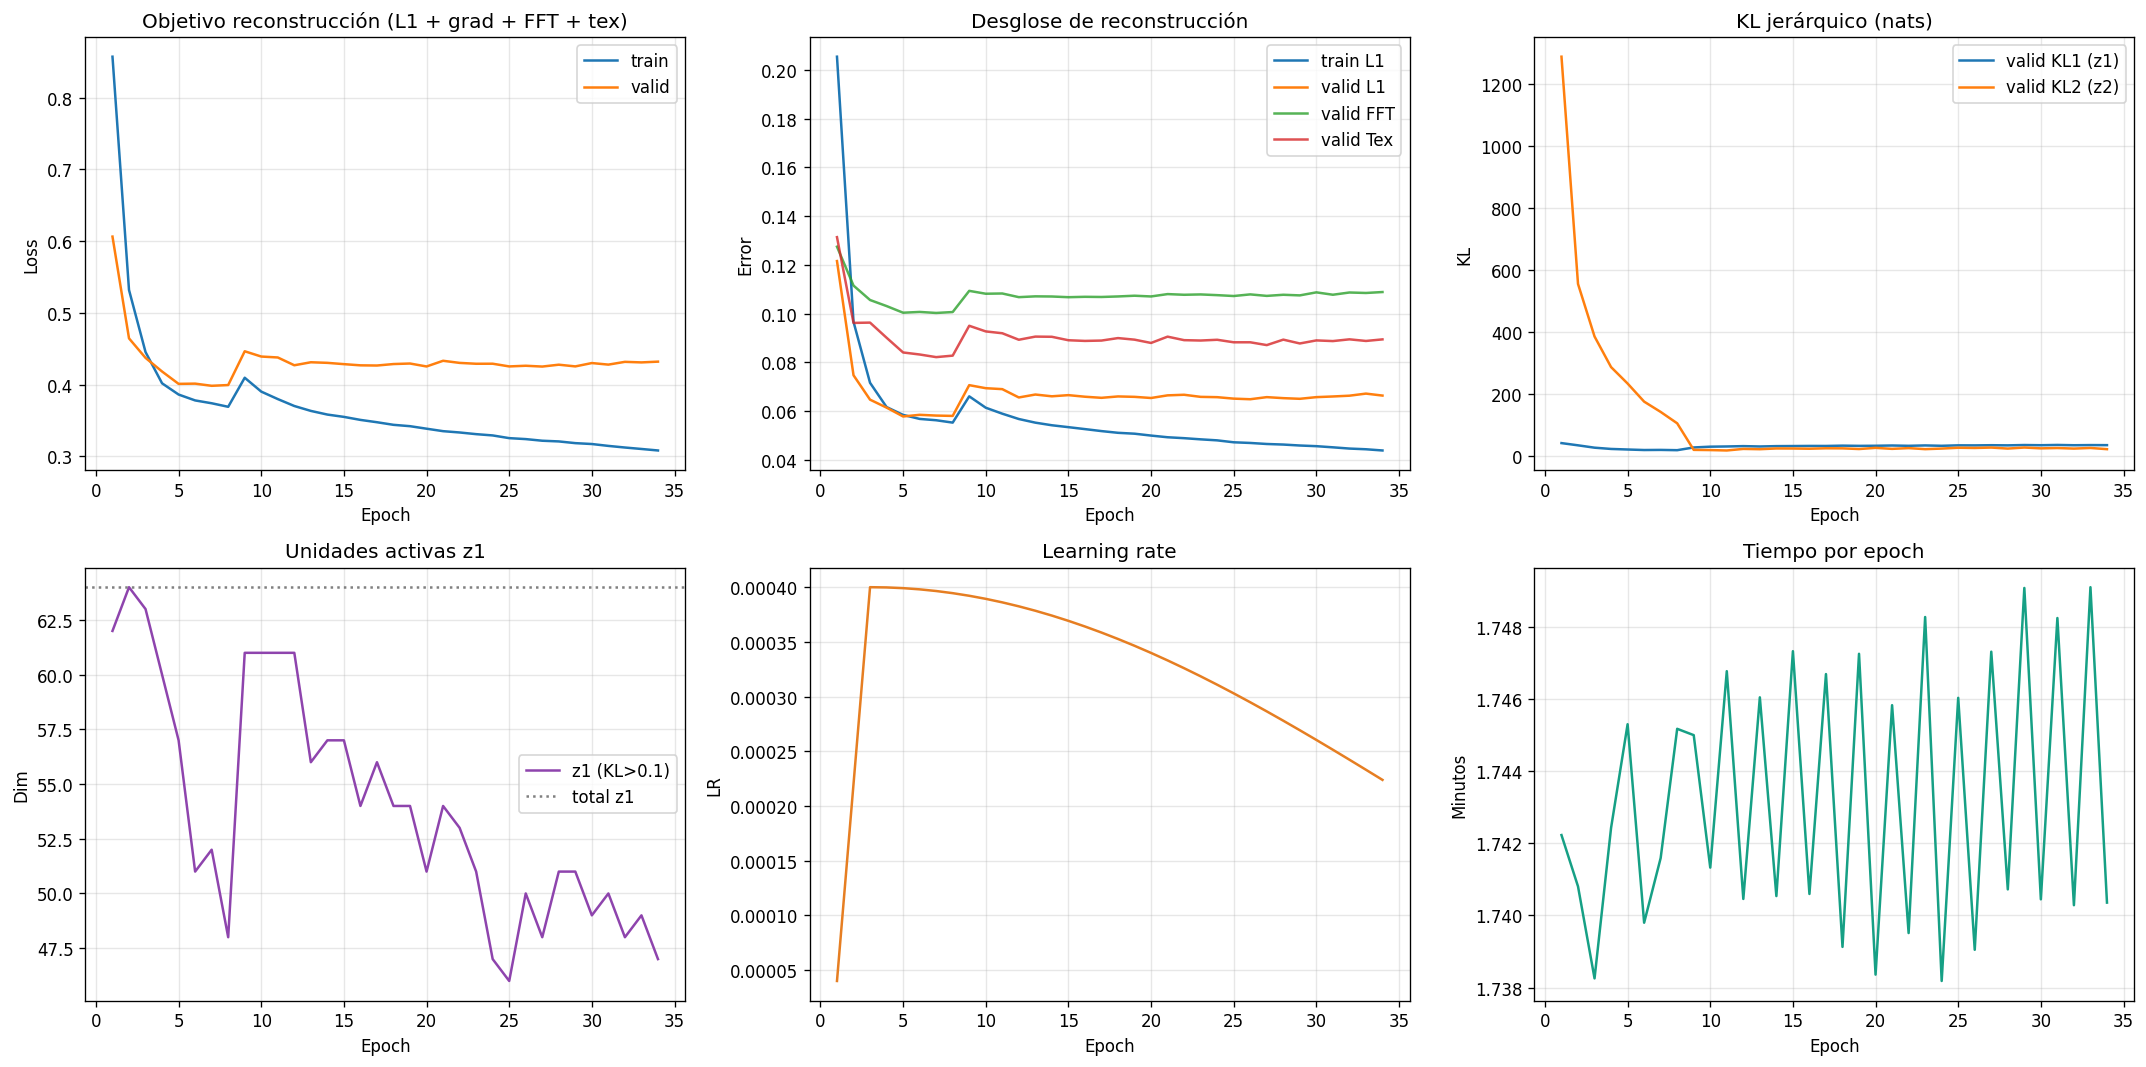

In [10]:
if len(historial_df) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), dpi=120)

    ax = axes[0, 0]
    ax.plot(historial_df['epoch'], historial_df['train_recon_obj'], label='train')
    ax.plot(historial_df['epoch'], historial_df['val_recon_obj'], label='valid')
    ax.set_title('Objetivo reconstrucción (L1 + grad + FFT + tex)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 1]
    ax.plot(historial_df['epoch'], historial_df['train_l1'], label='train L1')
    ax.plot(historial_df['epoch'], historial_df['val_l1'], label='valid L1')
    ax.plot(historial_df['epoch'], historial_df['val_fft'], label='valid FFT', alpha=0.8)
    ax.plot(historial_df['epoch'], historial_df['val_tex'], label='valid Tex', alpha=0.8)
    ax.set_title('Desglose de reconstrucción')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[0, 2]
    ax.plot(historial_df['epoch'], historial_df['val_kl1'], label='valid KL1 (z1)')
    ax.plot(historial_df['epoch'], historial_df['val_kl2'], label='valid KL2 (z2)')
    ax.set_title('KL jerárquico (nats)')
    ax.set_xlabel('Epoch'); ax.set_ylabel('KL')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 0]
    ax.plot(historial_df['epoch'], historial_df['active_units'], color='#8e44ad', label='z1 (KL>0.1)')
    ax.axhline(Z1_DIM, color='gray', linestyle=':', label='total z1')
    ax.set_title('Unidades activas z1')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Dim')
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1, 1]
    ax.plot(historial_df['epoch'], historial_df['lr'], color='#e67e22')
    ax.set_title('Learning rate')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR')
    ax.grid(alpha=0.3)

    ax = axes[1, 2]
    ax.plot(historial_df['epoch'], historial_df['epoch_time_s'] / 60, color='#16a085')
    ax.set_title('Tiempo por epoch')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Minutos')
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'curvas_entrenamiento.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('[ADVERTENCIA] No hay historial para graficar.')


## 11. Reconstrucción en validación

### ¿Qué se hace a continuación?
Se reconstruyen todas las muestras de `valid` usando `μ` (sin ruido, para una reconstrucción determinística) y se calculan:
- L1, MSE y L2 relativo en el espacio mel;
- las mismas métricas por familia;
- una grilla comparativa original / reconstruido / diferencia para una muestra de cada familia.

### ¿Por qué se hace?
La reconstrucción es la primera prueba de que el decoder aprendió algo útil. Si el VAE no puede reconstruir un mel real, difícilmente genere uno creíble. Comparar por familia muestra si alguna quedó relegada (por ejemplo, `keyboard`, que tiene menos muestras en valid). La grilla permite ver si el modelo está borroneando los armónicos o perdiendo el ataque.

Reconstruyendo valid:   0%|          | 0/36 [00:00<?, ?it/s]

[INFO] Reconstrucciones: (2297, 1, 128, 128)
[INFO] Métricas de reconstrucción por familia (VALID):
               l1      mse   l2_rel
brass     0.08851  0.01818  0.19755
guitar    0.05203  0.01748  0.14088
keyboard  0.04167  0.00831  0.10362
string    0.05959  0.01117  0.15986
[INFO] Global: L1=0.06441 | MSE=0.01538 | L2rel=0.16042


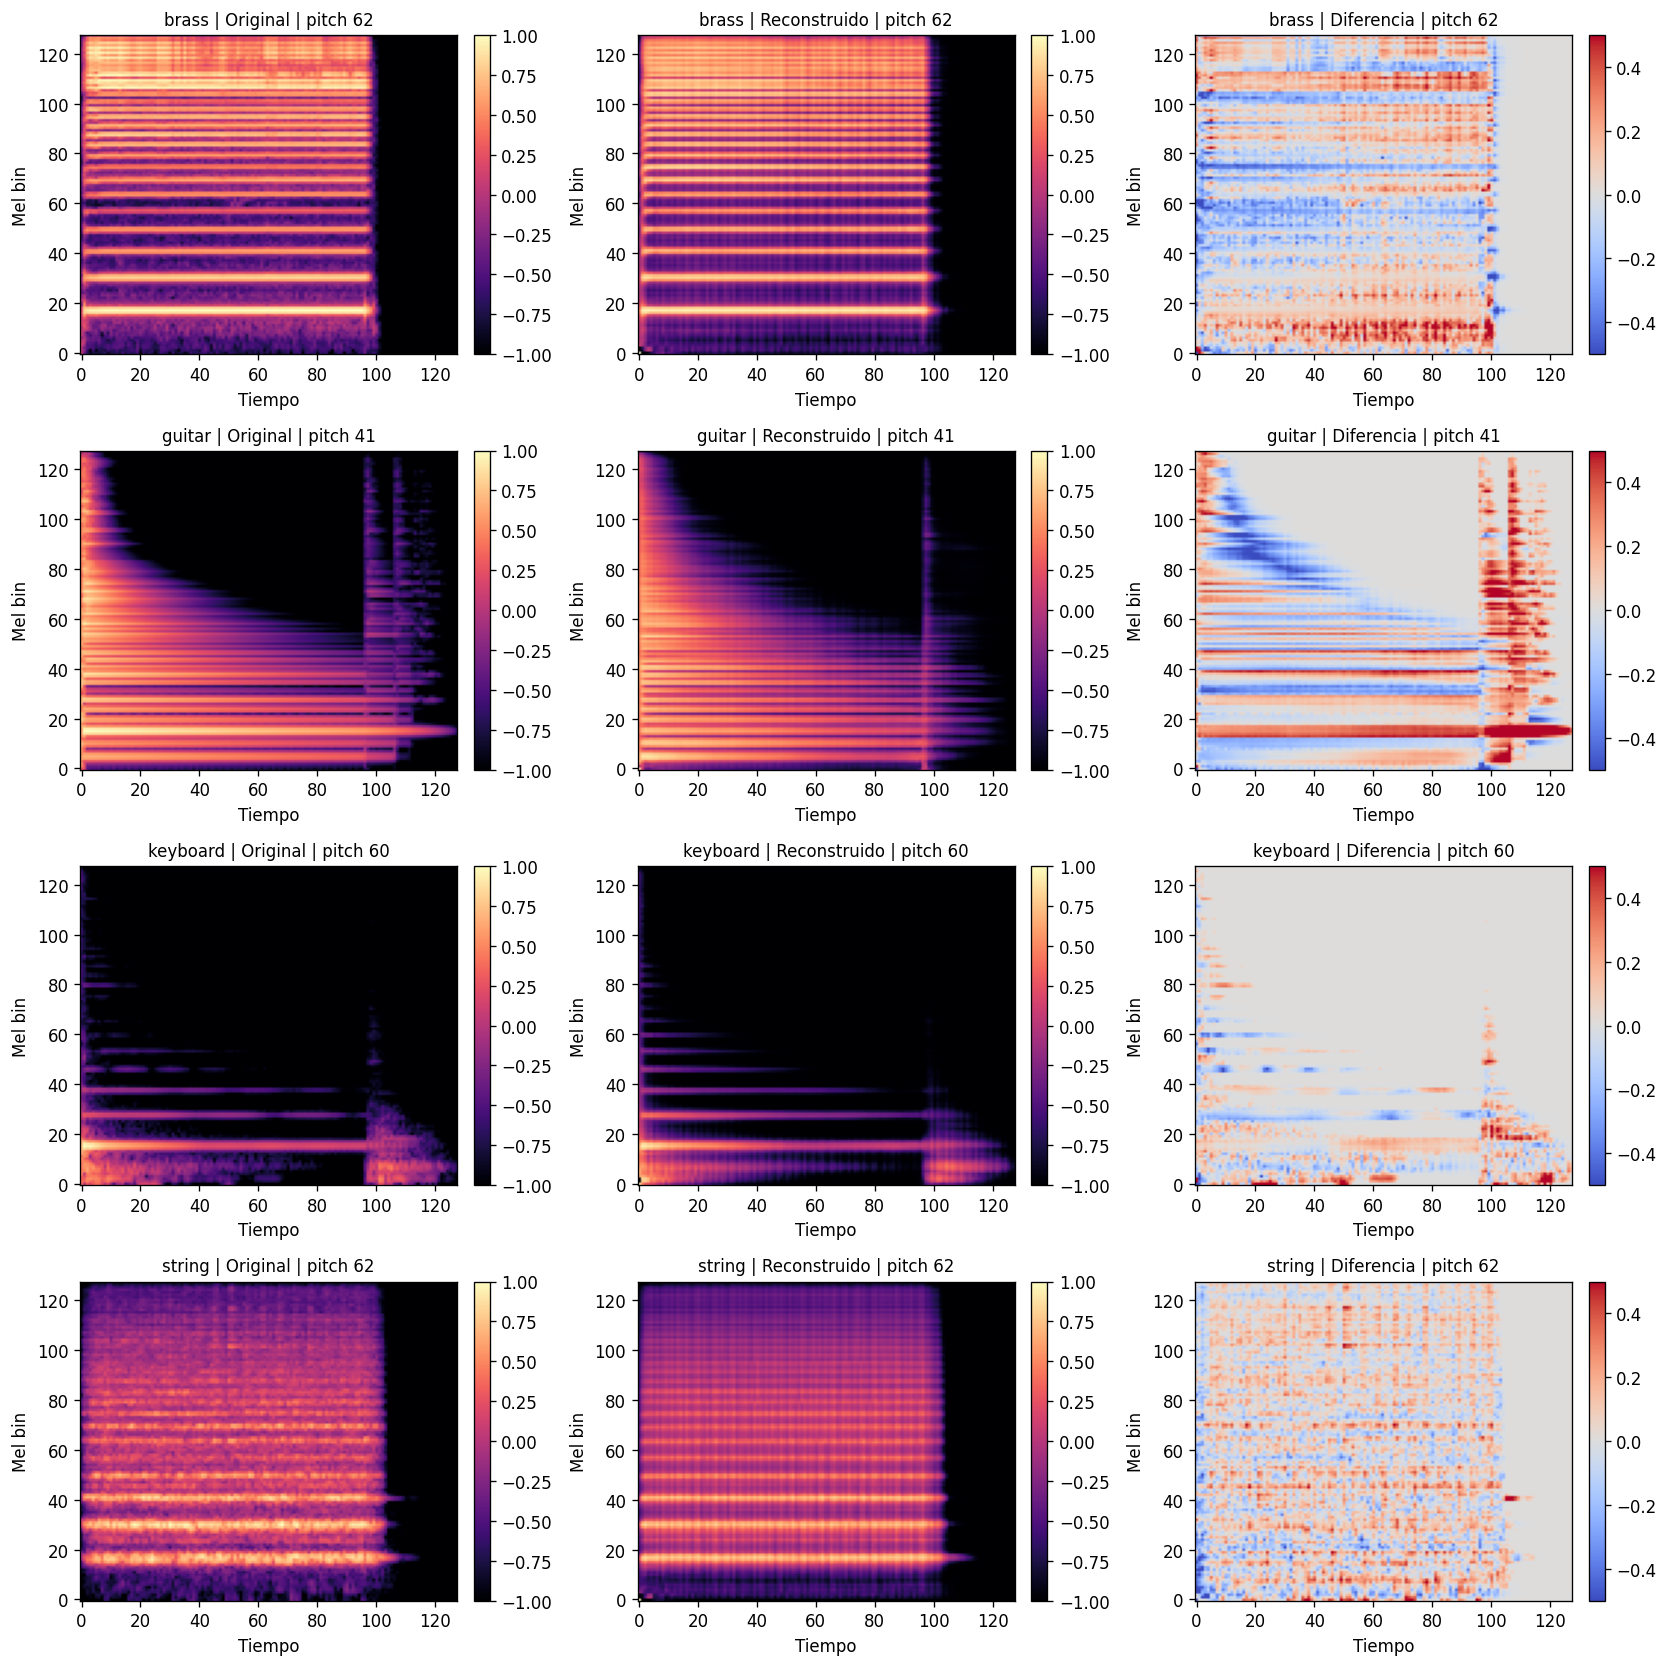

In [11]:
@torch.no_grad()
def reconstruir(model, loader):
    model.eval()
    origs, recs, fams, pits = [], [], [], []
    for xb, fb, pb in tqdm(loader, desc='Reconstruyendo valid', leave=False):
        xb = xb.to(device, non_blocking=True)
        fb = fb.to(device, non_blocking=True)
        pb = pb.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            rec, *_ = model(xb, fb, pb, deterministic=True)
        origs.append(xb.float().cpu())
        recs.append(rec.float().cpu())
        fams.append(fb.cpu())
        pits.append(pb.cpu())
    return torch.cat(origs), torch.cat(recs), torch.cat(fams), torch.cat(pits)


Xv_orig, Xv_rec, yv, pv = reconstruir(model, loader_val)
print(f'[INFO] Reconstrucciones: {tuple(Xv_rec.shape)}')

l1 = F.l1_loss(Xv_rec, Xv_orig, reduction='none').mean(dim=(1, 2, 3))
mse = F.mse_loss(Xv_rec, Xv_orig, reduction='none').mean(dim=(1, 2, 3))
l2_rel = torch.norm((Xv_orig - Xv_rec).flatten(1), dim=1) / (
    torch.norm(Xv_orig.flatten(1), dim=1) + 1e-8
)

df_recon = pd.DataFrame({
    'family': yv.numpy(),
    'l1': l1.numpy(),
    'mse': mse.numpy(),
    'l2_rel': l2_rel.numpy(),
})
tabla_recon = df_recon.groupby('family').mean()
tabla_recon.index = [FAMILY_NAMES[int(i)] for i in tabla_recon.index]
print('[INFO] Métricas de reconstrucción por familia (VALID):')
print(tabla_recon.round(5).to_string())
print(f'[INFO] Global: L1={l1.mean():.5f} | MSE={mse.mean():.5f} | L2rel={l2_rel.mean():.5f}')

fig, axes = plt.subplots(NUM_FAMILIES, 3, figsize=(14, 14), dpi=120)
for row, f in enumerate(range(NUM_FAMILIES)):
    idx = (yv == f).nonzero(as_tuple=True)[0]
    i = idx[0].item()
    orig = Xv_orig[i, 0].numpy()
    rec = Xv_rec[i, 0].numpy()
    diff = orig - rec
    paneles = [
        (orig, 'Original', 'magma', -1, 1),
        (rec, 'Reconstruido', 'magma', -1, 1),
        (diff, 'Diferencia', 'coolwarm', -0.5, 0.5),
    ]
    for col, (data, titulo, cmap, vmin, vmax) in enumerate(paneles):
        ax = axes[row, col]
        im = ax.imshow(data, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f'{FAMILY_NAMES[f]} | {titulo} | pitch {int(pv[i])}', fontsize=10)
        ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'reconstrucciones_valid.png', dpi=120, bbox_inches='tight')
plt.show()


## 12. Generación desde el prior (con calibración de temperatura en `valid`)

### ¿Qué se hace a continuación?
Se generan conjuntos candidatos de **80 muestras** (`4 familias × 5 pitches [36, 48, 60, 72, 84] × 4 semillas [42, 43, 44, 45]`) para distintas temperaturas `(τ₁, τ₂)` de muestreo (`z₁ ~ N(0, τ₁²I)`, `z₂ ~ p(z₂ | z₁, c, τ₂)`). Se comparan **exclusivamente contra `valid`** mediante FID-lite y diversidad L1 (exigiendo diversidad ≥ 0.14 para no colapsar a la media), sin tocar `test` ni el juez AST. El ganador se guarda en `muestras_generadas.npz`.

### ¿Por qué se hace?
En modelos generativos latentes, reducir levemente la temperatura (`τ ≈ 0.8–0.9`) evita muestrear en las colas poco pobladas del prior y mejora la fidelidad sin perder diversidad. Calibrar `(τ₁, τ₂)` sobre `valid` mantiene el protocolo completamente limpio.


[INFO] Calibrando temperatura en valid (sin tocar test ni juez):
  tau=(1.00, 1.00) -> pitch±1st=80.0% | FID-lite(valid)=0.1231 | div=0.2250 | hf_time=0.0208
  tau=(0.85, 0.90) -> pitch±1st=85.0% | FID-lite(valid)=0.1270 | div=0.1958 | hf_time=0.0212
  tau=(0.75, 0.80) -> pitch±1st=80.0% | FID-lite(valid)=0.1337 | div=0.1712 | hf_time=0.0217
[INFO] Temperatura elegida en valid: tau1=0.85, tau2=0.9
[INFO] Muestras generadas: (80, 1, 128, 128) | rango=[-1.000, 0.997] | finite=True
[INFO] Guardado: /kaggle/working/vae_output/muestras_generadas.npz


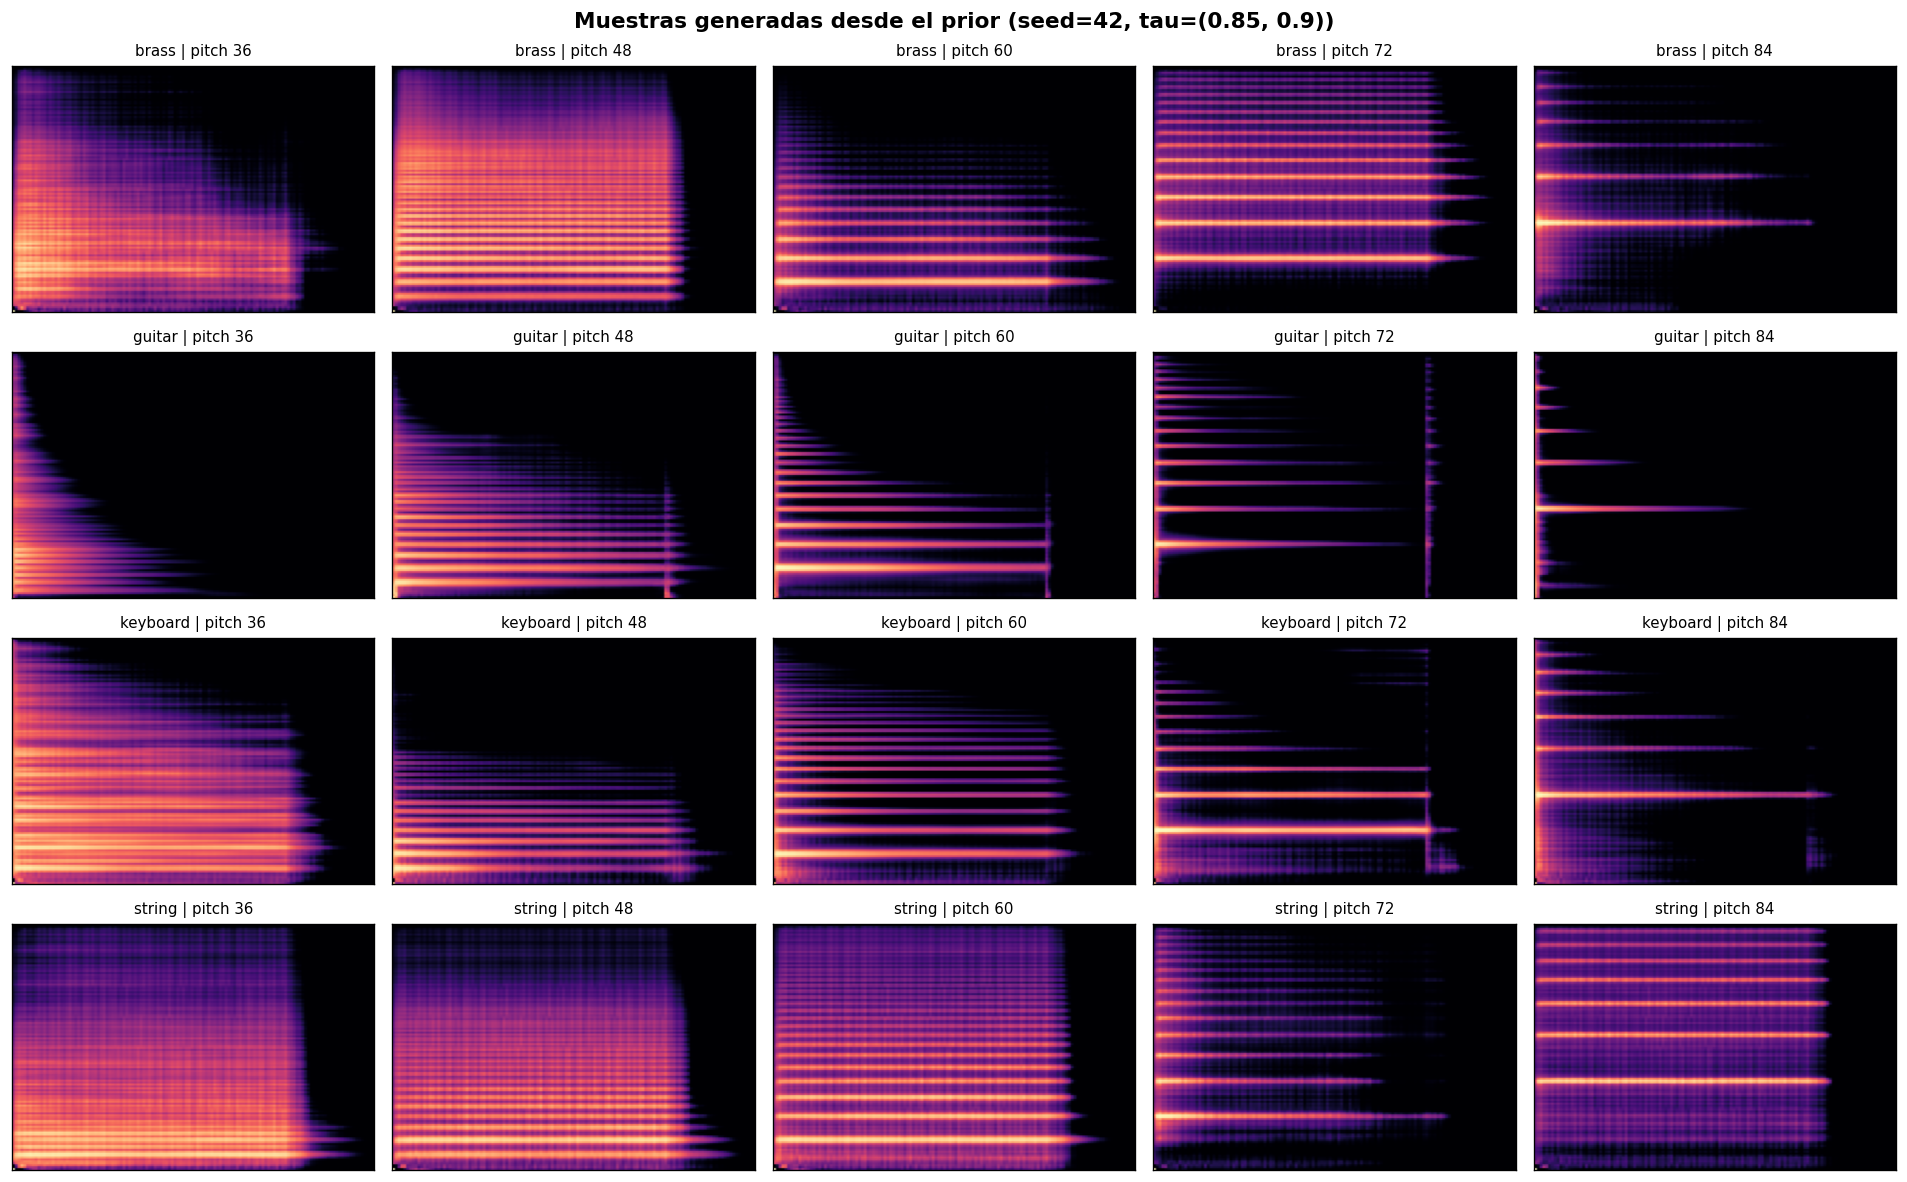

In [12]:
from scipy.linalg import sqrtm
from scipy.ndimage import uniform_filter1d

GEN_PITCHES = [36, 48, 60, 72, 84]
GEN_SEEDS = [42, 43, 44, 45]


def _features_mel_rapido(mels):
    x = mels[:, 0]
    feats = []
    for b in torch.chunk(x, 4, dim=1):
        feats.append(b.mean(dim=(1, 2)))
        feats.append(b.std(dim=(1, 2)))
    freqs = torch.linspace(0, 1, x.shape[1]).view(1, x.shape[1], 1)
    energy = (x + 1.0).clamp(min=0)
    total = energy.sum(dim=1) + 1e-8
    centroid = (energy * freqs).sum(dim=1) / total
    feats.append(centroid.mean(dim=1))
    feats.append(centroid.std(dim=1))
    cum = torch.cumsum(energy, dim=1)
    thr = 0.85 * cum[:, -1:, :]
    rolloff = (cum < thr).sum(dim=1).float() / x.shape[1]
    feats.append(rolloff.mean(dim=1))
    feats.append(rolloff.std(dim=1))
    feats.append(energy.mean(dim=(1, 2)))
    feats.append(energy.std(dim=(1, 2)))
    return torch.stack(feats, dim=1).numpy()


def _frechet(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    C1 = np.cov(a, rowvar=False) + 1e-6 * np.eye(a.shape[1])
    C2 = np.cov(b, rowvar=False) + 1e-6 * np.eye(b.shape[1])
    covmean = sqrtm(C1 @ C2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(C1 + C2 - 2 * covmean))


def _div_l1(mels):
    if len(mels) < 2:
        return float('nan')
    flat = mels.flatten(1)
    d = torch.cdist(flat, flat, p=1)
    n = len(flat)
    return float(d.sum().item() / (n * (n - 1) * flat.shape[1]))


@torch.no_grad()
def generar(model, families, pitches, seed, tau1=1.0, tau2=1.0):
    model.eval()
    torch.manual_seed(seed)
    z1 = tau1 * torch.randn(len(families), Z1_DIM, device=device)
    f = torch.tensor(families, dtype=torch.long, device=device)
    p = torch.tensor(pitches, dtype=torch.long, device=device)
    with torch.cuda.amp.autocast(enabled=use_amp):
        mels = model.sample_prior(z1, f, p, tau2=tau2)
    return mels.float().cpu()


def generar_grilla(model, tau1=1.0, tau2=1.0):
    all_mels, all_f, all_p, all_s = [], [], [], []
    for seed in GEN_SEEDS:
        fams = [f for f in range(NUM_FAMILIES) for _ in GEN_PITCHES]
        pits = [p for _ in range(NUM_FAMILIES) for p in GEN_PITCHES]
        mels = generar(model, fams, pits, seed, tau1=tau1, tau2=tau2)
        all_mels.append(mels)
        all_f.extend(fams)
        all_p.extend(pits)
        all_s.extend([seed] * len(fams))
    return (
        torch.cat(all_mels, dim=0),
        torch.tensor(all_f, dtype=torch.long),
        torch.tensor(all_p, dtype=torch.long),
        torch.tensor(all_s, dtype=torch.long),
    )


# Emparejado contra valid para calibrar temperatura sin ver test ni juez
_fams_ref = [f for _ in GEN_SEEDS for f in range(NUM_FAMILIES) for _ in GEN_PITCHES]
_pits_ref = [p for _ in GEN_SEEDS for _ in range(NUM_FAMILIES) for p in GEN_PITCHES]
_matched_val = []
for f, p in zip(_fams_ref, _pits_ref):
    idx = ((y_val == f) & (p_val == p)).nonzero(as_tuple=True)[0]
    if len(idx) == 0:
        idx_f = (y_val == f).nonzero(as_tuple=True)[0]
        idx = idx_f[(p_val[idx_f] - p).abs().argmin()].view(1)
    _matched_val.append(X_val[idx[0]])
_f_val_ref = _features_mel_rapido(torch.stack(_matched_val))

TAU_CANDIDATES = [(1.0, 1.0), (0.85, 0.90), (0.75, 0.80)]
candidatos_gen = {}
print('[INFO] Calibrando temperatura en valid (sin tocar test ni juez):')
for t1, t2 in TAU_CANDIDATES:
    gm, gf, gp, gs = generar_grilla(model, tau1=t1, tau2=t2)
    conds = sorted(set(zip(gf.tolist(), gp.tolist())))
    div = float(np.nanmean([_div_l1(gm[(gf == f) & (gp == p)]) for f, p in conds]))
    fd = _frechet(_features_mel_rapido(gm), _f_val_ref)
    hf_t = float(np.abs(gm[:, 0].numpy() - uniform_filter1d(gm[:, 0].numpy(), 5, axis=2))[:, :, 10:90].mean())
    aciertos_t = []
    for i in range(min(20, len(gm))):
        wav_t = vocoder.mel_norm_to_audio(gm[i, 0].numpy(), n_iter=32)
        f0_t = librosa.yin(wav_t, fmin=librosa.note_to_hz('C1'), fmax=librosa.note_to_hz('C7'), sr=SR, frame_length=2048, hop_length=512)
        f0_ok = f0_t[np.isfinite(f0_t) & (f0_t > 0)]
        mp = float(np.median(librosa.hz_to_midi(f0_ok))) if len(f0_ok) else -999.0
        aciertos_t.append(1.0 if abs(mp - int(gp[i])) <= 1.0 else 0.0)
    p1st_t = float(np.mean(aciertos_t))
    print(f'  tau=({t1:.2f}, {t2:.2f}) -> pitch±1st={p1st_t*100:.1f}% | FID-lite(valid)={fd:.4f} | div={div:.4f} | hf_time={hf_t:.4f}')
    candidatos_gen[(t1, t2)] = (p1st_t, fd, div, gm, gf, gp, gs)

elegibles = {k: v for k, v in candidatos_gen.items() if v[2] >= 0.12}
if not elegibles:
    elegibles = candidatos_gen
BEST_TAU = max(elegibles, key=lambda k: (round(elegibles[k][0], 2), -elegibles[k][1]))
_, _, _, gen_mels, gen_f, gen_p, gen_seeds = candidatos_gen[BEST_TAU]
print(f'[INFO] Temperatura elegida en valid: tau1={BEST_TAU[0]}, tau2={BEST_TAU[1]}')

print(f'[INFO] Muestras generadas: {tuple(gen_mels.shape)} | '
      f'rango=[{gen_mels.min():.3f}, {gen_mels.max():.3f}] | '
      f'finite={torch.isfinite(gen_mels).all().item()}')

np.savez_compressed(
    OUTPUT_DIR / 'muestras_generadas.npz',
    mels=gen_mels.numpy().astype(np.float32),
    families=gen_f.numpy().astype(np.int64),
    pitches=gen_p.numpy().astype(np.int64),
    seeds=gen_seeds.numpy().astype(np.int64),
)
print(f'[INFO] Guardado: {OUTPUT_DIR / "muestras_generadas.npz"}')

mask = (gen_seeds == GEN_SEEDS[0])
fig, axes = plt.subplots(NUM_FAMILIES, len(GEN_PITCHES), figsize=(16, 10), dpi=120)
for r, f in enumerate(range(NUM_FAMILIES)):
    for c, p in enumerate(GEN_PITCHES):
        idx = ((gen_f == f) & (gen_p == p) & mask).nonzero(as_tuple=True)[0][0]
        ax = axes[r, c]
        ax.imshow(gen_mels[idx, 0].numpy(), origin='lower', aspect='auto',
                  cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[f]} | pitch {p}', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f'Muestras generadas desde el prior (seed={GEN_SEEDS[0]}, tau={BEST_TAU})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'muestras_generadas.png', dpi=120, bbox_inches='tight')
plt.show()


## 13. Ejemplos de escucha: real vs reconstruido vs generado

### ¿Qué se hace a continuación?
Para una muestra de `valid` de cada familia se arma un trío con la **misma condición** `(familia, pitch)`, usando el pitch de `valid` más cercano a 60 para que las cuatro familias queden en un registro comparable:
1. mel real → Griffin-Lim;
2. mel real → encoder → decoder → Griffin-Lim;
3. `z ~ N(0, I)` + condición → decoder → Griffin-Lim.

Se guardan los WAVs en `vae_output/audio/`, se arma un ZIP y se muestran reproductores inline. También se grafica el trío de espectrogramas.

### ¿Por qué se hace?
Las métricas no alcanzan para saber si algo “suena a instrumento”. Escuchar el control real, la reconstrucción y la generación con el mismo vocoder permite separar tres fuentes de error: la pérdida del mel, la del decoder y la del Griffin-Lim. Los WAVs quedan como evidencia para el informe y para la escucha a ciegas.


--- BRASS | pitch 60 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):



--- GUITAR | pitch 60 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):


... (2 outputs left out)

3) Generado (prior):



--- STRING | pitch 60 ---
1) Real (mel real -> Griffin-Lim):


2) Reconstruido (VAE):


3) Generado (prior):


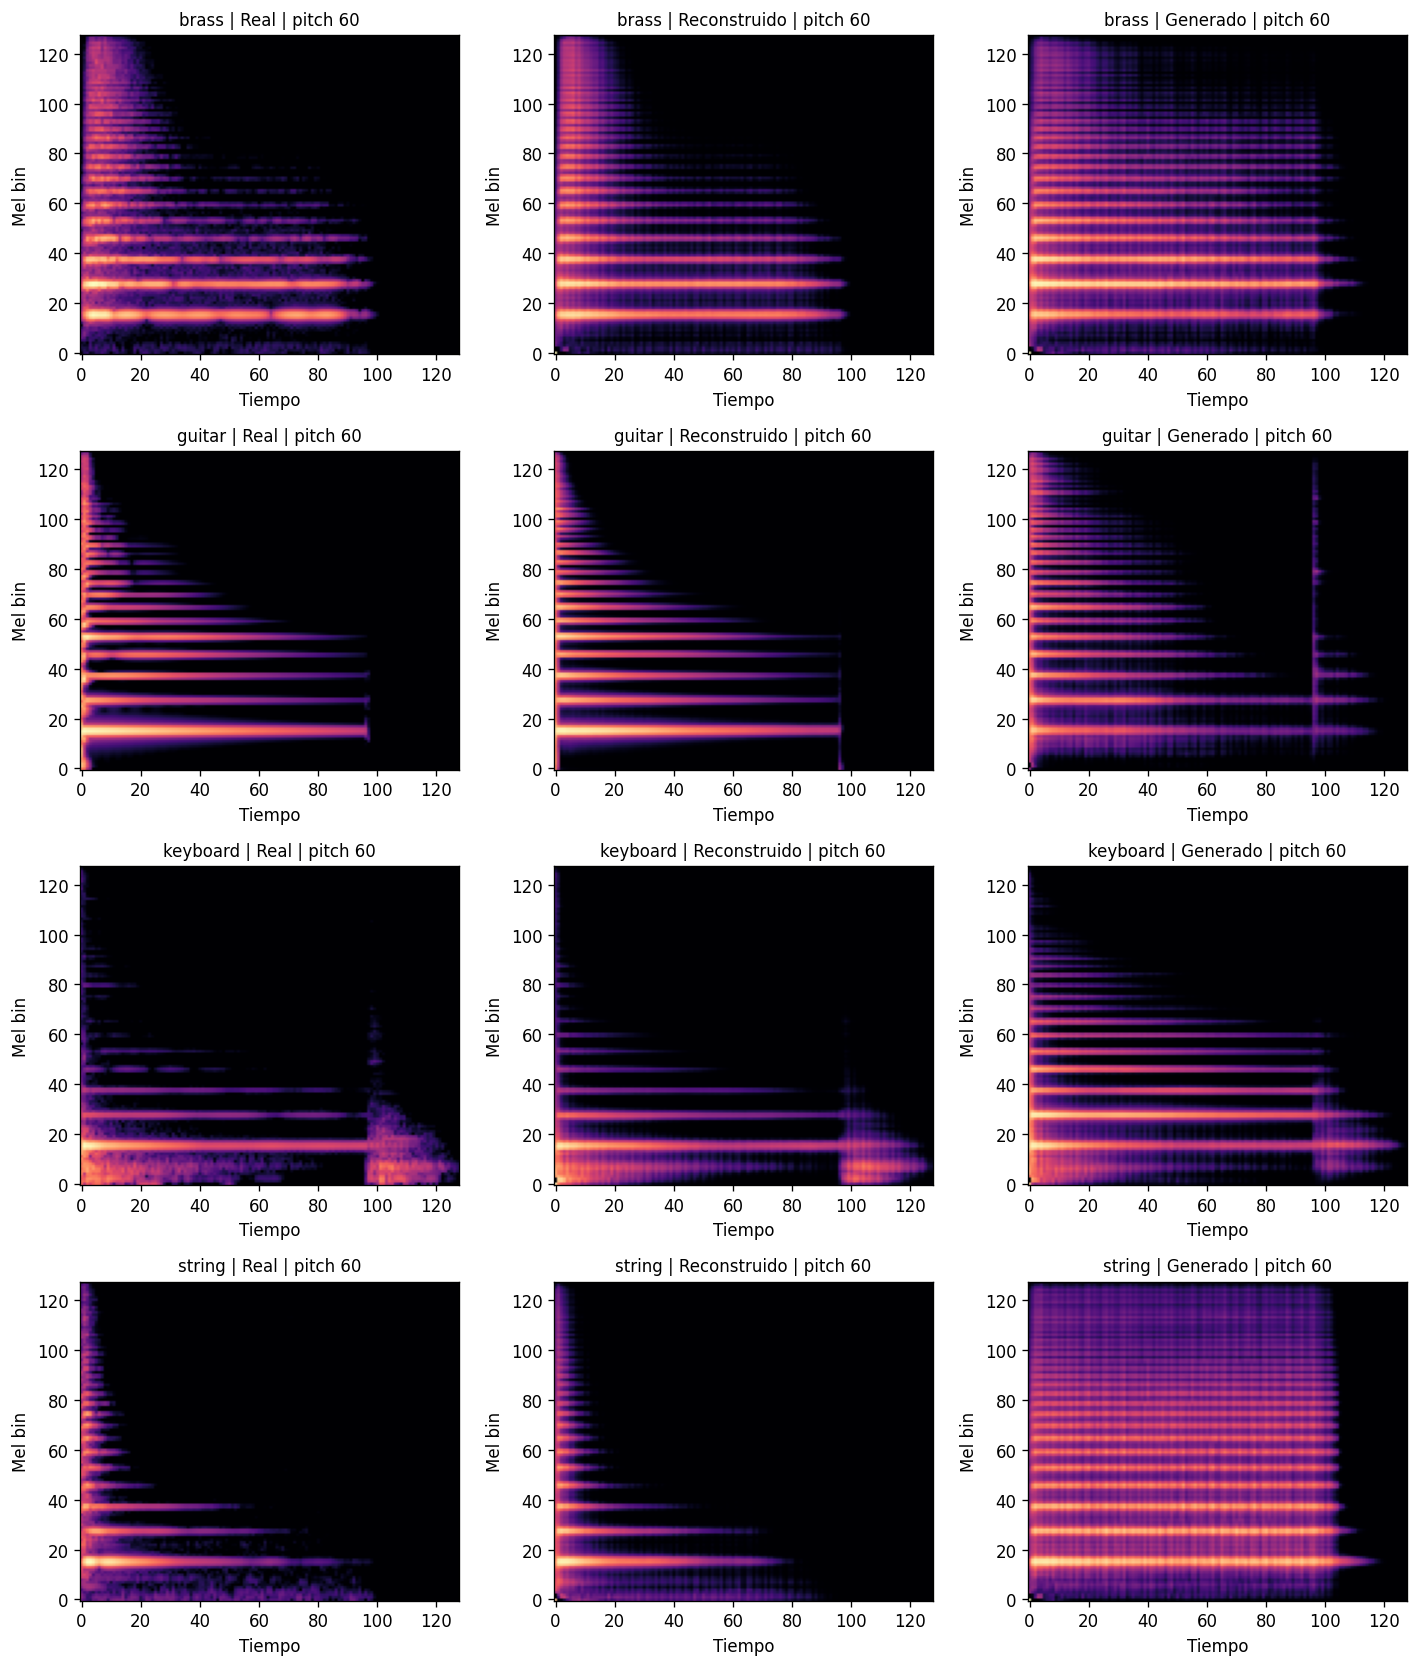

[INFO] ZIP de audios: /kaggle/working/vae_output/audio_ejemplos.zip


In [13]:
LISTEN_SEED = 42
ejemplos_audio = []

for p in AUDIO_DIR.glob('*.wav'):
    p.unlink()

for f in range(NUM_FAMILIES):
    idx_f = (yv == f).nonzero(as_tuple=True)[0]
    pitches_f = pv[idx_f]
    p_use = int(pitches_f[(pitches_f - 60).abs().argmin()].item())

    idx = idx_f[pv[idx_f] == p_use]
    i = idx[0].item()

    real_mel = Xv_orig[i, 0].numpy()
    recon_mel = Xv_rec[i, 0].numpy()
    gen_mel = generar(model, [f], [p_use], LISTEN_SEED, tau1=BEST_TAU[0], tau2=BEST_TAU[1])[0, 0].numpy()

    wav_real = vocoder.mel_norm_to_audio(real_mel, n_iter=250)
    wav_recon = vocoder.mel_norm_to_audio(recon_mel, n_iter=250)
    wav_gen = vocoder.mel_norm_to_audio(gen_mel, n_iter=250)

    nombre = FAMILY_NAMES[f]
    sf.write(AUDIO_DIR / f'real_{nombre}_p{p_use}.wav', wav_real, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'recon_{nombre}_p{p_use}.wav', wav_recon, SR, subtype='PCM_16')
    sf.write(AUDIO_DIR / f'gen_{nombre}_p{p_use}_s{LISTEN_SEED}.wav', wav_gen, SR, subtype='PCM_16')

    ejemplos_audio.append({
        'family': f, 'pitch': p_use,
        'real': real_mel, 'recon': recon_mel, 'gen': gen_mel,
    })

    print(f'\n--- {nombre.upper()} | pitch {p_use} ---')
    print('1) Real (mel real -> Griffin-Lim):')
    ipd.display(ipd.Audio(wav_real, rate=SR))
    print('2) Reconstruido (VAE):')
    ipd.display(ipd.Audio(wav_recon, rate=SR))
    print('3) Generado (prior):')
    ipd.display(ipd.Audio(wav_gen, rate=SR))

fig, axes = plt.subplots(len(ejemplos_audio), 3, figsize=(12, 14), dpi=120)
for row, ej in enumerate(ejemplos_audio):
    for col, (key, titulo) in enumerate([
        ('real', 'Real'), ('recon', 'Reconstruido'), ('gen', 'Generado'),
    ]):
        ax = axes[row, col]
        ax.imshow(ej[key], origin='lower', aspect='auto', cmap='magma', vmin=-1, vmax=1)
        ax.set_title(f'{FAMILY_NAMES[ej["family"]]} | {titulo} | pitch {ej["pitch"]}',
                     fontsize=10)
        ax.set_xlabel('Tiempo'); ax.set_ylabel('Mel bin')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparativa_mels_escucha.png', dpi=120, bbox_inches='tight')
plt.show()

with zipfile.ZipFile(OUTPUT_DIR / 'audio_ejemplos.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(AUDIO_DIR.glob('*.wav')):
        z.write(p, arcname=p.name)
print(f'[INFO] ZIP de audios: {OUTPUT_DIR / "audio_ejemplos.zip"}')


In [14]:
for ej in ejemplos_audio:
    m = ej['real']
    print(f"familia {ej['family']} | pitch {ej['pitch']} | mel real: media={m.mean():.4f} std={m.std():.4f}")

familia 0 | pitch 60 | mel real: media=-0.7337 std=0.4137
familia 1 | pitch 60 | mel real: media=-0.8132 std=0.3986
familia 2 | pitch 60 | mel real: media=-0.8562 std=0.3204
familia 3 | pitch 60 | mel real: media=-0.8874 std=0.2845


## 14. Métricas objetivas sin juez

### ¿Qué se hace a continuación?
Se calculan métricas que **no dependen del clasificador AST**:
- **Error de pitch**: se estima la F0 del audio generado con `librosa.pyin`, se convierte a MIDI y se compara con el pitch pedido (error absoluto en semitonos y porcentaje dentro de ±1 semitono).
- **Baseline media**: para cada `(familia, pitch)` se usa el mel promedio de `train`; se calcula su error de pitch y su diversidad (0 por definición).
- **Diversidad**: diferencia absoluta media por píxel entre pares de muestras generadas con la misma condición, comparada con muestras reales de `valid` (0 = todas iguales; 2 = máximo contraste).
- **Fréchet mel-lite**: distancia de Fréchet sobre 14 features mel (energía por bandas, centroide, rolloff) entre generado y real emparejado.

### ¿Por qué se hace?
El juez mide “familia”, pero no dice nada sobre si la nota tiene la altura pedida ni sobre si el modelo colapsó a la media. Estas métricas cubren justamente eso y permiten comparar VAE contra baseline sin depender de otro modelo. La distancia tipo FID es una versión reducida de la métrica de la sección 8; la versión completa, sobre embeddings del juez, va en el notebook del torneo.

In [15]:
def estimar_pitch_midi(wav, sr=SR):
    f0, voiced, _ = librosa.pyin(
        np.asarray(wav, dtype=np.float32),
        fmin=librosa.midi_to_hz(PITCH_MIN),
        fmax=librosa.midi_to_hz(PITCH_MAX + 6),
        sr=sr, frame_length=N_FFT, hop_length=HOP,
    )
    if f0 is None:
        return np.nan
    tiempos = librosa.times_like(f0, sr=sr, hop_length=HOP)
    mask = voiced & np.isfinite(f0) & (tiempos >= 0.15) & (tiempos <= 2.5)
    if mask.sum() == 0:
        mask = voiced & np.isfinite(f0)
    if mask.sum() == 0:
        return np.nan
    f_med = float(np.median(f0[mask]))
    return float(69.0 + 12.0 * np.log2(f_med / 440.0))


print('[INFO] Estimando pitch de las muestras generadas...')
pitch_gen = []
for i in tqdm(range(len(gen_mels)), desc='Pitch VAE', leave=False):
    wav = vocoder.mel_norm_to_audio(gen_mels[i, 0].numpy(), n_iter=64)
    pitch_gen.append(estimar_pitch_midi(wav))
pitch_gen = np.asarray(pitch_gen)
err_gen = np.abs(pitch_gen - gen_p.numpy().astype(np.float64))

# ── Baseline media por (familia, pitch) ─────────────────────────────────────
condiciones = sorted(set(zip(gen_f.tolist(), gen_p.tolist())))

def media_condicion(f, p):
    mask = (y_train == f) & (p_train == p)
    if mask.sum() >= 5:
        return X_train[mask].mean(dim=0)
    return X_train[y_train == f].mean(dim=0)

print(f'[INFO] Calculando baseline media para {len(condiciones)} condiciones...')
medias = {c: media_condicion(*c) for c in condiciones}
baseline_mels = torch.stack([medias[(int(f), int(p))] for f, p in zip(gen_f, gen_p)])

pitch_base = []
for c in tqdm(condiciones, desc='Pitch baseline', leave=False):
    wav = vocoder.mel_norm_to_audio(medias[c][0].numpy(), n_iter=64)
    pitch_base.append(estimar_pitch_midi(wav))
pitch_base_map = dict(zip(condiciones, pitch_base))
pitch_base = np.asarray([pitch_base_map[(int(f), int(p))] for f, p in zip(gen_f, gen_p)])
err_base = np.abs(pitch_base - gen_p.numpy().astype(np.float64))

# ── Diversidad ──────────────────────────────────────────────────────────────
def diversidad_l1(mels):
    """Diferencia absoluta media por píxel entre pares de muestras (0 a 2)."""
    if len(mels) < 2:
        return float('nan')
    flat = mels.flatten(1)
    d = torch.cdist(flat, flat, p=1)
    n = len(flat)
    return float(d.sum().item() / (n * (n - 1) * flat.shape[1]))

div_gen = float(np.nanmean([
    diversidad_l1(gen_mels[(gen_f == f) & (gen_p == p)]) for f, p in condiciones
]))

div_real_list = []
for f, p in condiciones:
    idx = ((yv == f) & (pv == p)).nonzero(as_tuple=True)[0][:4]
    if len(idx) >= 2:
        div_real_list.append(diversidad_l1(Xv_orig[idx]))
div_real = float(np.nanmean(div_real_list)) if div_real_list else float('nan')

# ── Real emparejado por condición ───────────────────────────────────────────
matched = []
for f, p in zip(gen_f.tolist(), gen_p.tolist()):
    idx = ((yv == f) & (pv == p)).nonzero(as_tuple=True)[0]
    if len(idx) == 0:
        idx_f = (yv == f).nonzero(as_tuple=True)[0]
        idx = idx_f[(pv[idx_f] - p).abs().argmin()].view(1)
    matched.append(Xv_orig[idx[0]])
matched = torch.stack(matched)

# ── Features mel y distancia de Fréchet ─────────────────────────────────────
def features_mel(mels):
    x = mels[:, 0]
    feats = []
    for b in torch.chunk(x, 4, dim=1):
        feats.append(b.mean(dim=(1, 2)))
        feats.append(b.std(dim=(1, 2)))
    freqs = torch.linspace(0, 1, x.shape[1]).view(1, x.shape[1], 1)
    energy = (x + 1.0).clamp(min=0)
    total = energy.sum(dim=1) + 1e-8
    centroid = (energy * freqs).sum(dim=1) / total
    feats.append(centroid.mean(dim=1))
    feats.append(centroid.std(dim=1))
    cum = torch.cumsum(energy, dim=1)
    thr = 0.85 * cum[:, -1:, :]
    rolloff = (cum < thr).sum(dim=1).float() / x.shape[1]
    feats.append(rolloff.mean(dim=1))
    feats.append(rolloff.std(dim=1))
    feats.append(energy.mean(dim=(1, 2)))
    feats.append(energy.std(dim=(1, 2)))
    return torch.stack(feats, dim=1).numpy()

from scipy.linalg import sqrtm

def frechet_distance(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    C1 = np.cov(a, rowvar=False) + 1e-6 * np.eye(a.shape[1])
    C2 = np.cov(b, rowvar=False) + 1e-6 * np.eye(b.shape[1])
    covmean = sqrtm(C1 @ C2)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(np.sum((mu1 - mu2) ** 2) + np.trace(C1 + C2 - 2 * covmean))

f_real = features_mel(matched)
f_gen = features_mel(gen_mels)
f_base = features_mel(baseline_mels)
fd_gen = frechet_distance(f_gen, f_real)
fd_base = frechet_distance(f_base, f_real)

metricas_gen = {
    'n_muestras': int(len(gen_mels)),
    'vae': {
        'pitch_mae_st': float(np.nanmean(err_gen)),
        'pitch_medae_st': float(np.nanmedian(err_gen)),
        'pct_dentro_1_st': float(np.nanmean(err_gen <= 1.0)),
        'diversidad_l1': div_gen,
        'frechet_mel_lite': fd_gen,
    },
    'baseline_media': {
        'pitch_mae_st': float(np.nanmean(err_base)),
        'pitch_medae_st': float(np.nanmedian(err_base)),
        'pct_dentro_1_st': float(np.nanmean(err_base <= 1.0)),
        'diversidad_l1': 0.0,
        'frechet_mel_lite': fd_base,
    },
    'real_matched': {
        'diversidad_l1': div_real,
    },
}

print('\n[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====')
print(f'VAE            : pitch MAE={metricas_gen["vae"]["pitch_mae_st"]:.2f} st | '
      f'±1st={metricas_gen["vae"]["pct_dentro_1_st"]*100:.1f}% | '
      f'div={div_gen:.4f} | FID-lite={fd_gen:.2f}')
print(f'Baseline media : pitch MAE={metricas_gen["baseline_media"]["pitch_mae_st"]:.2f} st | '
      f'±1st={metricas_gen["baseline_media"]["pct_dentro_1_st"]*100:.1f}% | '
      f'div=0.0000 | FID-lite={fd_base:.2f}')
print(f'Real valid     : diversidad={div_real:.4f}')


# ── Textura temporal (hf_time) por familia: real vs VAE vs baseline ──────────
def _hf_time(arr):
    # arr: (N, 128, 128)
    sm = uniform_filter1d(arr, size=5, axis=2)
    return float(np.abs(arr - sm)[:, :, 10:90].mean())

print('\n[INFO] Rugosidad temporal hf_time (frames 10..90) por familia:')
hf_tabla = {}
for f_id, fname in enumerate(FAMILY_NAMES):
    r_hf = _hf_time(Xv_orig[yv == f_id, 0].numpy())
    v_hf = _hf_time(gen_mels[gen_f == f_id, 0].numpy())
    b_hf = _hf_time(baseline_mels[gen_f == f_id, 0].numpy())
    hf_tabla[fname] = {'real': r_hf, 'vae': v_hf, 'baseline': b_hf}
    print(f'  {fname:8s}: real={r_hf:.4f} | VAE={v_hf:.4f} | baseline={b_hf:.4f}')
metricas_gen['hf_time_por_familia'] = hf_tabla

metricas_recon = {
    'l1': float(l1.mean()),
    'mse': float(mse.mean()),
    'l2_rel': float(l2_rel.mean()),
    'por_familia': tabla_recon.to_dict(orient='index'),
}

[INFO] Estimando pitch de las muestras generadas...


Pitch VAE:   0%|          | 0/80 [00:00<?, ?it/s]

[INFO] Calculando baseline media para 20 condiciones...


Pitch baseline:   0%|          | 0/20 [00:00<?, ?it/s]


[INFO] ===== MÉTRICAS OBJETIVAS (sin juez) =====
VAE            : pitch MAE=0.45 st | ±1st=98.8% | div=0.1958 | FID-lite=0.13
Baseline media : pitch MAE=0.07 st | ±1st=100.0% | div=0.0000 | FID-lite=0.28
Real valid     : diversidad=0.2424

[INFO] Rugosidad temporal hf_time (frames 10..90) por familia:
  brass   : real=0.0405 | VAE=0.0305 | baseline=0.0062
  guitar  : real=0.0032 | VAE=0.0068 | baseline=0.0026
  keyboard: real=0.0105 | VAE=0.0098 | baseline=0.0028
  string  : real=0.0278 | VAE=0.0379 | baseline=0.0061


## 15. Espacio latente

### ¿Qué se hace a continuación?
Se codifican 2.000 muestras de `valid` y se proyectan sus `μ` a 2D con PCA, coloreando por familia y por pitch.

### ¿Por qué se hace?
Si el condicionamiento funciona, el latente debería organizarse por familia y mostrar un gradiente por pitch. Si todas las familias están mezcladas y el pitch no varía, el decoder está ignorando la condición. Es una figura interpretable y muy útil para la defensa.

[INFO] Varianza explicada (z1): 30.2%


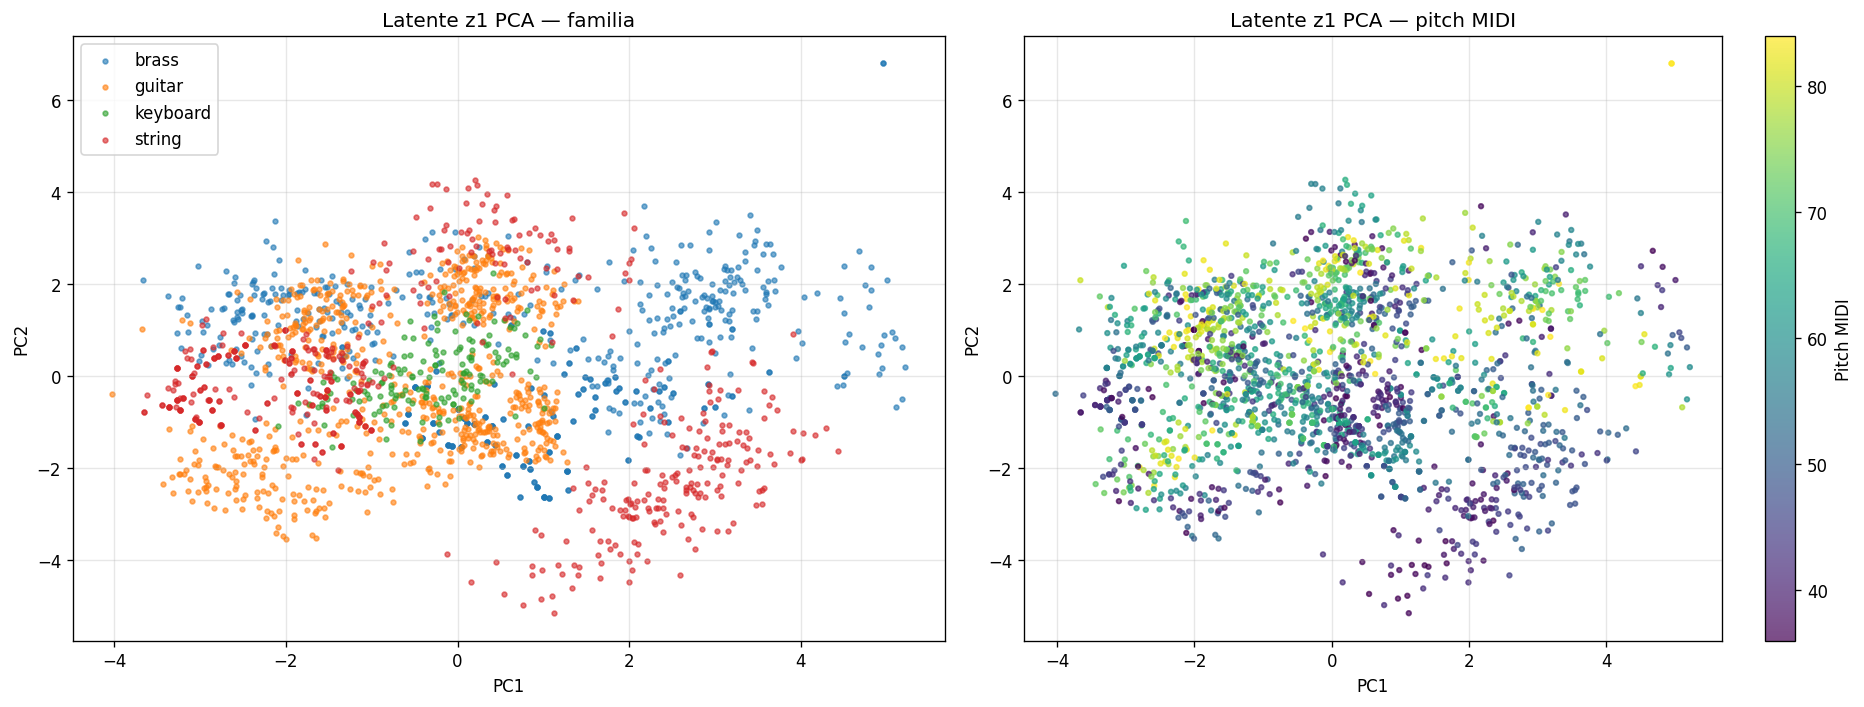

In [16]:
from sklearn.decomposition import PCA

n_lat = min(2000, len(X_val))
torch.manual_seed(SEED)
idx_lat = torch.randperm(len(X_val))[:n_lat]
mus = []
model.eval()
with torch.no_grad():
    for i in range(0, n_lat, 256):
        j = idx_lat[i:i + 256]
        mu, _ = model.encode(
            X_val[j].to(device), y_val[j].to(device), p_val[j].to(device)
        )
        mus.append(mu.float().cpu())
Z = torch.cat(mus).numpy()

pca = PCA(n_components=2, random_state=SEED)
Z2 = pca.fit_transform(Z)
print(f'[INFO] Varianza explicada (z1): {pca.explained_variance_ratio_.sum()*100:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)
for f in range(NUM_FAMILIES):
    m = (y_val[idx_lat].numpy() == f)
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=8, alpha=0.6, label=FAMILY_NAMES[f])
axes[0].set_title('Latente z1 PCA — familia')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend(); axes[0].grid(alpha=0.3)

sc = axes[1].scatter(Z2[:, 0], Z2[:, 1], c=p_val[idx_lat].numpy(),
                     cmap='viridis', s=8, alpha=0.7)
axes[1].set_title('Latente z1 PCA — pitch MIDI')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.colorbar(sc, ax=axes[1], label='Pitch MIDI')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'latentes_pca.png', dpi=120, bbox_inches='tight')
plt.show()


## 16. Inventario, métricas consolidadas y conclusiones

### ¿Qué se hace a continuación?
Se guarda `metricas_objetivas.json` con la configuración, las métricas de reconstrucción y de generación. Se lista el contenido de `vae_output/` y se imprime un resumen final.

### ¿Por qué se hace?
El notebook de evaluación final (torneo VAE vs Flow Matching vs baseline) necesita las muestras y las métricas en un formato estable, sin volver a entrenar. El inventario confirma que todos los artefactos quedaron escritos antes de cerrar la sesión de Kaggle.

In [17]:
metricas_final = {
    'config': config_actual,
    'temperatura_elegida': {'tau1': BEST_TAU[0], 'tau2': BEST_TAU[1]},
    'reconstruccion': metricas_recon,
    'generacion': metricas_gen,
    'kl_valid_best': {'kl1': kl1_best, 'kl2': kl2_best, 'total': kl_best},
    'condiciones_generadas': {
        'pitches': GEN_PITCHES,
        'seeds': GEN_SEEDS,
        'familias': FAMILY_NAMES,
    },
    'nota': 'El juez AST se aplica en el notebook de evaluacion final (torneo). '
            'Aca no se usa para evitar fuga de criterio y ahorrar cuota.',
}

with open(OUTPUT_DIR / 'metricas_objetivas.json', 'w', encoding='utf-8') as f:
    json.dump(to_py(metricas_final), f, ensure_ascii=False, indent=2)

print(f'[INFO] Métricas guardadas en: {OUTPUT_DIR / "metricas_objetivas.json"}')
print(f'[INFO] Muestras generadas: {OUTPUT_DIR / "muestras_generadas.npz"}')
print(f'[INFO] Audios: {OUTPUT_DIR / "audio_ejemplos.zip"}')

print('\n[INFO] Archivos generados:')
print('-' * 70)
for archivo in sorted(OUTPUT_DIR.rglob('*')):
    if archivo.is_file():
        tam = archivo.stat().st_size / 1024
        rel = archivo.relative_to(OUTPUT_DIR)
        print(f'  {str(rel):<45} {tam:>9.1f} KB')
print('-' * 70)

print('\n[INFO] ===== RESUMEN NB03 (C-VAE jerárquico) =====')
print(f'  Épocas entrenadas     : {len(historial_df)}')
if len(historial_df) > 0:
    df_post = historial_df[historial_df['epoch'] >= KL_WARMUP_EPOCHS]
    if len(df_post) == 0:
        df_post = historial_df
    mejor = df_post.loc[df_post['val_recon_obj'].idxmin()]
    print(f'  Mejor val_recon_obj   : {mejor["val_recon_obj"]:.5f} (L1={mejor["val_l1"]:.5f}, epoch {int(mejor["epoch"])})')
    print(f'  Unidades activas z1   : {int(historial_df["active_units"].iloc[-1])}/{Z1_DIM}')
    print(f'  Betas finales         : ({historial_df["beta1"].iloc[-1]:.1e}, {historial_df["beta2"].iloc[-1]:.1e})')
print(f'  KL valid (mejor)      : KL1={kl1_best:.1f} (obj {KL1_TARGET:.0f}) | KL2={kl2_best:.1f} (obj {KL2_TARGET:.0f})')
print(f'  Temperatura elegida   : tau=({BEST_TAU[0]}, {BEST_TAU[1]})')
print(f'  Reconstrucción L1     : {metricas_recon["l1"]:.5f}')
print(f'  Pitch MAE VAE         : {metricas_gen["vae"]["pitch_mae_st"]:.2f} semitonos')
print(f'  Pitch MAE baseline    : {metricas_gen["baseline_media"]["pitch_mae_st"]:.2f} semitonos')
print(f'  Diversidad VAE        : {metricas_gen["vae"]["diversidad_l1"]:.4f}')
print(f'  Diversidad real       : {metricas_gen["real_matched"]["diversidad_l1"]:.4f}')
print(f'  FID-lite VAE          : {metricas_gen["vae"]["frechet_mel_lite"]:.2f}')
print(f'  FID-lite baseline     : {metricas_gen["baseline_media"]["frechet_mel_lite"]:.2f}')

print('\n[INFO] Próximo paso:')
print('  1. Revisar curvas, reconstrucciones, hf_time y audios.')
print('  2. Descargar vae_output/ (o hacer Quick Save en Kaggle).')
print('  3. Usar muestras_generadas.npz en el torneo final con el juez AST (05).')


[INFO] Métricas guardadas en: /kaggle/working/vae_output/metricas_objetivas.json
[INFO] Muestras generadas: /kaggle/working/vae_output/muestras_generadas.npz
[INFO] Audios: /kaggle/working/vae_output/audio_ejemplos.zip

[INFO] Archivos generados:
----------------------------------------------------------------------
  audio/gen_brass_p60_s42.wav                       125.0 KB
  audio/gen_guitar_p60_s42.wav                      125.0 KB
  audio/gen_keyboard_p60_s42.wav                    125.0 KB
  audio/gen_string_p60_s42.wav                      125.0 KB
  audio/real_brass_p60.wav                          125.0 KB
  audio/real_guitar_p60.wav                         125.0 KB
  audio/real_keyboard_p60.wav                       125.0 KB
  audio/real_string_p60.wav                         125.0 KB
  audio/recon_brass_p60.wav                         125.0 KB
  audio/recon_guitar_p60.wav                        125.0 KB
  audio/recon_keyboard_p60.wav                      125.0 KB
  audio/rec

## Conclusiones del Notebook 03

Con la ejecución completa se obtienen:

1. **C-VAE condicional entrenado** con familia + pitch, checkpoints y curvas.
2. **Reconstrucciones determinísticas** sobre `valid`, con métricas por familia.
3. **80 muestras generadas** desde el prior para condiciones y semillas fijas.
4. **Ejemplos de escucha** real / reconstruido / generado con el mismo Griffin-Lim.
5. **Métricas objetivas sin juez**: error de pitch, diversidad y distancia tipo FID.
6. **Espacio latente** en 2D para interpretar el condicionamiento.

El juez AST queda deliberadamente fuera de este notebook. En el notebook final se cargan `muestras_generadas.npz` (VAE), las muestras equivalentes de Flow Matching y las reales de `test`, y se evalúan todas con el mismo juez y el mismo protocolo.

**Siguiente paso:** `04_generador_flow_matching.ipynb`.

In [18]:
print((X_train >= 0.999).float().mean().item())

6.813897198298946e-05
